# Лабораторная работа 3. Кластеризация

**Выполнил:** Гладышев Р.М.  
**Проверил:** Антонянц Е.Н.  
**Датасет:** Mall Customer Segmentation Data (Kaggle) — данные о клиентах торгового центра: пол, возраст, годовой доход и индекс трат.  
**Задача:** кластеризация (сегментация) клиентов по трём числовым признакам: возраст (`Age`), годовой доход (`Income`, тыс. долл.) и индекс трат (`Spending`, 1–100). Метки классов отсутствуют.  
**План работы:** описательный анализ и проверка условий применимости кластеризации → стандартизация → матрица диаграмм рассеивания и обоснование методов → подбор числа кластеров (локоть, силуэт, дендрограмма) → K-means и иерархическая кластеризация (метод Уорда) → внутренние и внешние метрики качества → влияние параметров и устойчивость → визуализация (PCA) и интерпретация кластеров → сравнение методов → заключение.

## Введение

**Цель работы** — изучить алгоритмы кластеризации, приобрести навыки оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**

1. загрузить датасет и провести дескриптивный анализ: размерность, типы признаков, пропуски, распределения (гистограммы), информационная значимость признаков;
2. проверить условия применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов;
3. выполнить стандартизацию числовых признаков и обосновать выбор метода масштабирования;
4. построить матрицу диаграмм рассеивания, оценить число и форму кластеров, аргументированно выбрать два метода кластеризации;
5. подобрать число кластеров *k* методом локтя, анализом силуэта и по дендрограмме;
6. реализовать кластеризацию двумя методами (K-means и иерархическая кластеризация), рассчитать внутренние и внешние метрики качества, расстояния между кластерами, компактность, центры;
7. исследовать влияние параметров метода (числа кластеров *k*, инициализации, способа объединения кластеров) и устойчивость разбиения;
8. визуализировать кластеры (PCA), интерпретировать центры кластеров, сравнить результаты двух методов.

In [1]:
%matplotlib inline
import warnings, random
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform, cdist

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score, rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure)
from sklearn.metrics.cluster import pair_confusion_matrix

SEED = 42                                   # единое зерно для воспроизводимости
random.seed(SEED); np.random.seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
print("scikit-learn:", __import__("sklearn").__version__)

scikit-learn: 1.9.1


**Пояснение к блоку кода.** Подключаем библиотеки: `pandas`, `numpy`, `scipy` — данные, статистика, иерархическая кластеризация и расстояния; `matplotlib`, `seaborn` — графики; `scikit-learn` — стандартизация, PCA, алгоритмы кластеризации (`KMeans`, `AgglomerativeClustering`) и метрики качества. Константа `SEED = 42` и вызовы `random.seed`, `np.random.seed` фиксируют случайные числа, чтобы эксперименты воспроизводились; во всех случайных алгоритмах дополнительно задаётся `random_state`. Предупреждения отключены, настроен единый формат вывода чисел.

## 1. Загрузка данных и дескриптивный анализ

In [2]:
DATA_PATH = "Mall_Customers.csv"
df = pd.read_csv(DATA_PATH)

print("Размер таблицы (строки, столбцы):", df.shape)
df.info()
miss = df.isna().sum().to_frame("пропусков")
miss["доля, %"] = miss["пропусков"] / len(df) * 100
print("\nПропуски по столбцам:")
display(miss.T)
print("Полных дубликатов строк:", df.duplicated().sum())
print("Повторяющихся CustomerID:", df["CustomerID"].duplicated().sum())
print("\nРаспределение по полу:")
display(df["Gender"].value_counts().to_frame("количество").assign(**{"доля, %": df["Gender"].value_counts(normalize=True) * 100}))
df.head()

Размер таблицы (строки, столбцы): (200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Пропуски по столбцам:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
пропусков,0.0000,0.0000,0.0000,0.0000,0.0000
"доля, %",0.0000,0.0000,0.0000,0.0000,0.0000


Полных дубликатов строк: 0
Повторяющихся CustomerID: 0

Распределение по полу:


,количество,"доля, %"
Gender,,
Female,112,56.0000
Male,88,44.0000


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Пояснение к блоку кода.** Загружаем таблицу и выводим сведения: размер, типы столбцов (`info`), число и долю пропусков, число дубликатов (строк и идентификаторов клиентов) и распределение по полу. Это первичный анализ: он показывает, нужна ли очистка данных.

**Вывод.** В таблице 200 строк и 5 столбцов. `CustomerID`, `Age`, `Annual Income (k$)` и `Spending Score (1-100)` — целые числа, `Gender` — категориальный (строковый) признак. Пропусков и дубликатов нет, идентификаторы уникальны, очистка не требуется. Пол распределён почти поровну: 112 женщин (56%) и 88 мужчин (44%). `CustomerID` — порядковый номер, информации о сходстве клиентов не несёт, поэтому исключается из анализа. `Gender` — бинарный признак: после стандартизации он имел бы непропорционально большой вес в евклидовом расстоянии и «разрезал» бы данные на два пола, а не на группы по поведению; поэтому в кластеризации он не участвует, а используется **только для интерпретации** (доля женщин в кластерах). Для кластеризации берутся три числовых признака.

## Описание датасета

**Mall Customer Segmentation Data** — учебный набор данных о **200 клиентах** торгового центра (карта лояльности).

| Признак | Описание | Тип / единицы | Роль |
|---|---|---|---|
| `CustomerID` | номер клиента | целое | не используется |
| `Gender` | пол клиента (Female / Male) | категориальный | интерпретация |
| `Age` | возраст | лет (18–70) | признак кластеризации |
| `Annual Income (k$)` → `Income` | годовой доход | тыс. долл. (15–137) | признак кластеризации |
| `Spending Score (1-100)` → `Spending` | индекс трат, присваиваемый торговым центром по поведению и покупкам клиента | баллы 1–100 | признак кластеризации |

Датасет не содержит целевой переменной: это классическая задача **сегментации клиентов** (обучение без учителя).

In [3]:
# короткие имена столбцов; CustomerID — идентификатор, Gender — категориальный признак (в кластеризации не участвует)
df = df.rename(columns={"Annual Income (k$)": "Income", "Spending Score (1-100)": "Spending"})
FEATURES = ["Age", "Income", "Spending"]   # признаки для кластеризации

desc = df[FEATURES].describe().T
desc["skew"] = df[FEATURES].skew()
desc["CV, %"] = desc["std"] / desc["mean"] * 100      # коэффициент вариации
desc

,count,mean,std,min,25%,50%,75%,max,skew,"CV, %"
Age,200.0000,38.8500,13.9690,18.0000,28.7500,36.0000,49.0000,70.0000,0.4856,35.9563
Income,200.0000,60.5600,26.2647,15.0000,41.5000,61.5000,78.0000,137.0000,0.3218,43.3698
Spending,200.0000,50.2000,25.8235,1.0000,34.7500,50.0000,73.0000,99.0000,-0.0472,51.4413


**Пояснение к блоку кода.** Столбцы переименованы в короткие имена (`Income`, `Spending`), задан список признаков кластеризации. Для трёх признаков вычислена описательная статистика (`describe`) с коэффициентом асимметрии (`skew`) и коэффициентом вариации (`CV = σ/μ`).

**Вывод.** Все три признака имеют сопоставимый, но различный разброс: возраст 18–70 лет (среднее 38.9, σ ≈ 14.0), доход 15–137 тыс. (среднее 60.6, σ ≈ 26.3), индекс трат 1–99 (среднее 50.2, σ ≈ 25.8). Коэффициенты вариации 36%, 43% и 51% — признаки достаточно изменчивы, т.е. различают клиентов. Асимметрия небольшая (0.49; 0.32; −0.05): распределения близки к симметричным, у возраста и дохода есть умеренный правый «хвост». Единицы измерения разные (годы, тысячи долларов, баллы), поэтому масштаб нужно выравнивать.

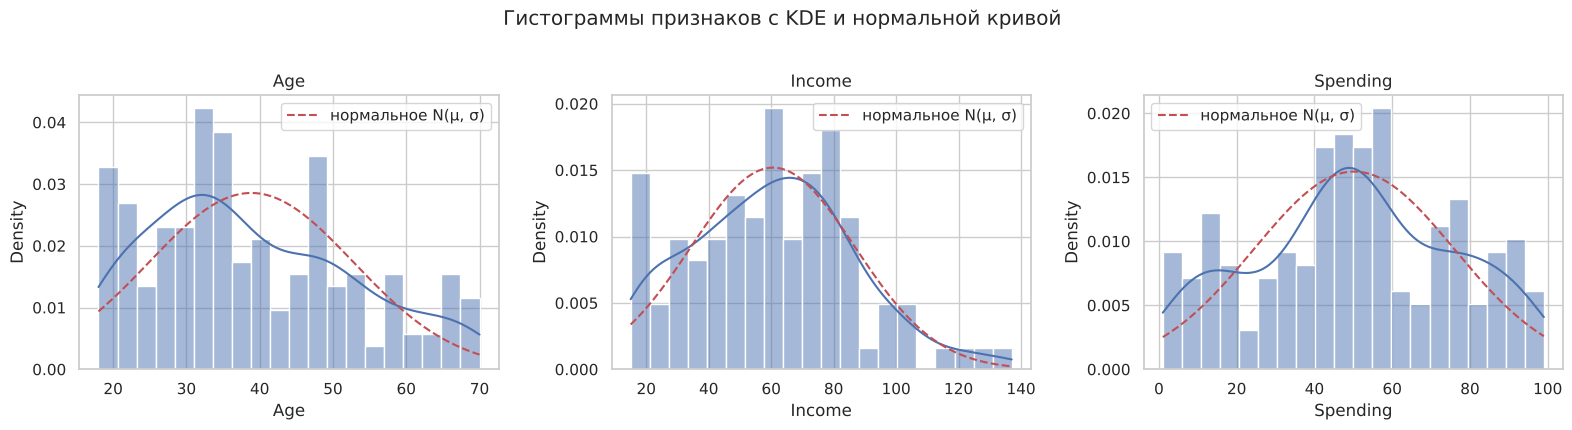

,асимметрия,эксцесс,W (Шапиро–Уилк),p-value
признак,,,,
Age,0.4819,-0.6848,0.9516,0.0000
Income,0.3194,-0.1259,0.9784,0.0035
Spending,-0.0469,-0.8360,0.9695,0.0002


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, col in zip(axes, FEATURES):
    sns.histplot(df[col], bins=20, kde=True, stat="density", color="#4C72B0", ax=ax)
    mu, sd = df[col].mean(), df[col].std()
    xs = np.linspace(df[col].min(), df[col].max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color="#C44E52", ls="--", label="нормальное N(μ, σ)")
    ax.set_title(col); ax.legend()
plt.suptitle("Гистограммы признаков с KDE и нормальной кривой", y=1.02)
plt.tight_layout(); plt.show()

norm_rows = []
for col in FEATURES:
    w, p = stats.shapiro(df[col])
    norm_rows.append({"признак": col, "асимметрия": stats.skew(df[col]), "эксцесс": stats.kurtosis(df[col]),
                      "W (Шапиро–Уилк)": w, "p-value": p})
pd.DataFrame(norm_rows).set_index("признак")

**Пояснение к блоку кода.** Для каждого признака строим гистограмму с оценкой плотности (KDE) и накладываем плотность нормального распределения с теми же средним и стандартным отклонением; в таблице приводим асимметрию, эксцесс и критерий Шапиро–Уилка (нулевая гипотеза — нормальность). Цель — оценить близость распределений к нормальному.

**Вывод.** Строго нормальным не является ни один признак: критерий Шапиро–Уилка отвергает нормальность (p = 3·10⁻⁶ для `Age`, 0.004 для `Income`, 2·10⁻⁴ для `Spending`; при n = 200 критерий чувствителен даже к небольшим отклонениям). По форме: `Age` — унимодальное с правым хвостом (асимметрия 0.48); `Income` — почти нормальное, колоколообразное (асимметрия 0.32, эксцесс ≈ −0.1) с небольшим правым хвостом до 137; `Spending` — «плоское» (эксцесс −0.84) с намёком на несколько горбов — около 15, 50 и 75–80 баллов, т.е. не одна нормальная совокупность, а смесь групп. Сильных перекосов нет, преобразования (логарифм и т.п.) не требуются. Для алгоритмов, использованных ниже (K-means, метод Уорда), строгая нормальность признаков не обязательна.

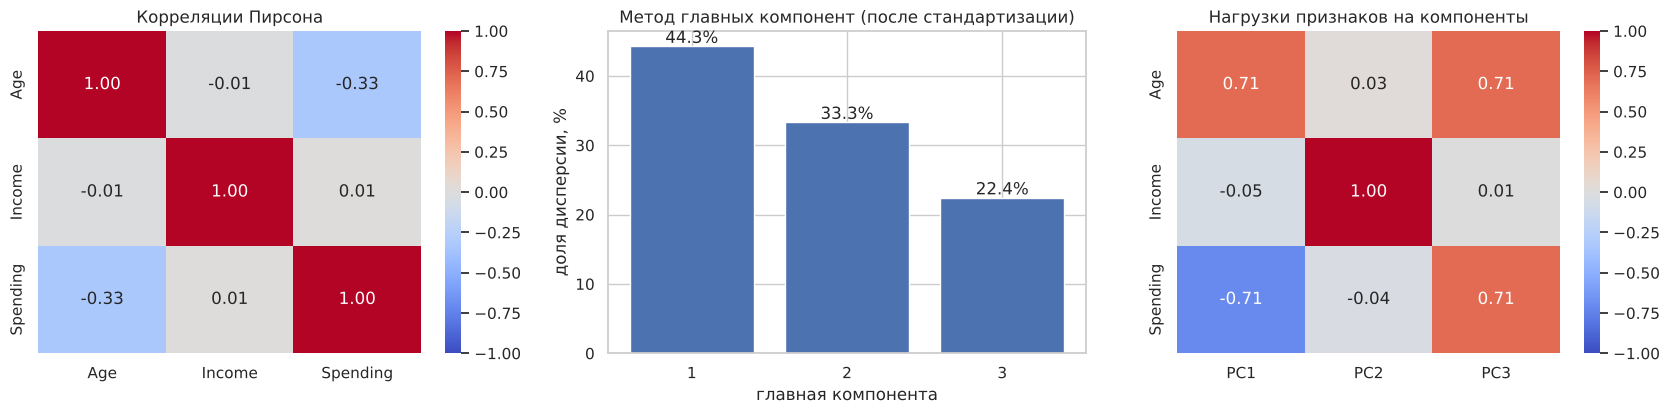

,среднее (Female),среднее (Male),p-value (Манн–Уитни)
признак,,,
Age,38.0982,39.8068,0.6242
Income,59.2500,62.2273,0.4144
Spending,51.5268,48.5114,0.5713


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Корреляции Пирсона")

Xtmp = StandardScaler().fit_transform(df[FEATURES])
pca_full = PCA().fit(Xtmp)
axes[1].bar(range(1, 4), pca_full.explained_variance_ratio_ * 100, color="#4C72B0")
for i, v in enumerate(pca_full.explained_variance_ratio_ * 100):
    axes[1].text(i + 1, v + 0.5, f"{v:.1f}%", ha="center")
axes[1].set_xticks([1, 2, 3]); axes[1].set_xlabel("главная компонента"); axes[1].set_ylabel("доля дисперсии, %")
axes[1].set_title("Метод главных компонент (после стандартизации)")

loadings = pd.DataFrame(pca_full.components_.T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Нагрузки признаков на компоненты")
plt.tight_layout(); plt.show()

# различия по полу (пол — демографическая характеристика, а не метка класса)
gender_rows = []
for col in FEATURES:
    a, b = df.loc[df.Gender == "Female", col], df.loc[df.Gender == "Male", col]
    gender_rows.append({"признак": col, "среднее (Female)": a.mean(), "среднее (Male)": b.mean(),
                        "p-value (Манн–Уитни)": stats.mannwhitneyu(a, b).pvalue})
display(pd.DataFrame(gender_rows).set_index("признак"))

**Пояснение к блоку кода.** Информационную значимость признаков оцениваем тремя способами: (1) корреляционная матрица — не дублируют ли признаки друг друга; (2) метод главных компонент (PCA) после стандартизации — сколько независимой информации несёт каждое направление и как признаки в него входят; (3) сравнение признаков по полу (критерий Манна–Уитни) — различается ли поведение мужчин и женщин (пол — не метка класса, а демографическая характеристика).

**Вывод.** Корреляции между признаками слабые: `Age`–`Spending` = −0.33 (с возрастом индекс трат умеренно снижается), `Age`–`Income` ≈ −0.01, `Income`–`Spending` ≈ 0.01. Признаки не дублируют друг друга — каждый несёт собственную информацию. Это подтверждает PCA: три компоненты объясняют 44.3%, 33.3% и 22.4% дисперсии, т.е. дисперсия распределена почти равномерно, и отбрасывать признаки нельзя. Первая компонента — «возраст против трат» (нагрузки 0.71 и −0.71), вторая — практически чистый доход (нагрузка 1.00). Пол по трём признакам различий не даёт (p = 0.62; 0.41; 0.57 > 0.05), что оправдывает его исключение из кластеризации. Все три признака значимы и включаются в анализ.

## 2. Проверка условий применимости кластеризации

,нижняя граница,верхняя граница,выбросов по IQR,выбросов по |z|>3,max |z|
признак,,,,,
Age,-1.6250,79.3750,0,0,2.2355
Income,-13.2500,132.7500,2,0,2.9177
Spending,-22.6250,130.3750,0,0,1.9100


Клиенты с выбросом по Income (IQR):


,CustomerID,Gender,Age,Income,Spending
198,199,Male,32,137,18
199,200,Male,30,137,83


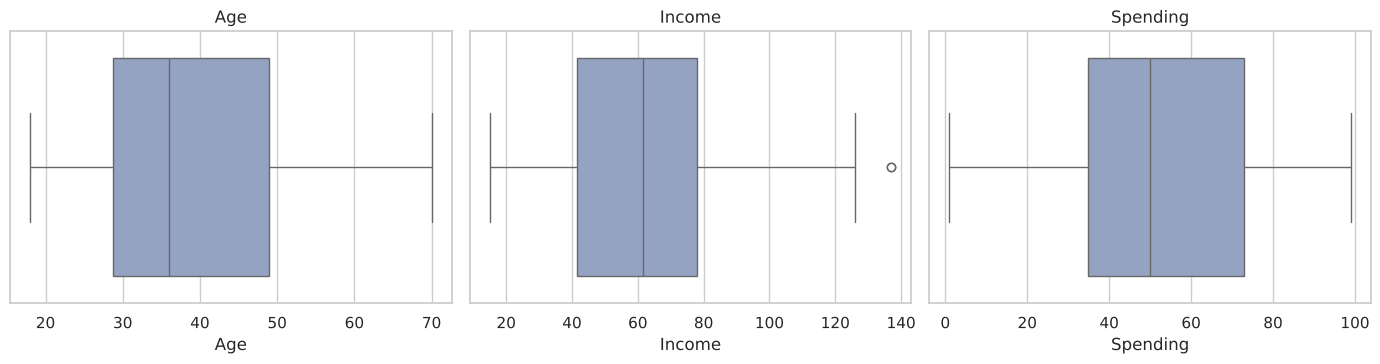

Статистика Хопкинса для данных: 0.692 ± 0.037  (контроль — равномерный шум: 0.481)


In [6]:
# 1) выбросы: правило 1.5·IQR и |z| > 3
out_rows = []
for col in FEATURES:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = stats.zscore(df[col])
    out_rows.append({"признак": col, "нижняя граница": lo, "верхняя граница": hi,
                     "выбросов по IQR": int(((df[col] < lo) | (df[col] > hi)).sum()),
                     "выбросов по |z|>3": int((np.abs(z) > 3).sum()), "max |z|": np.abs(z).max()})
display(pd.DataFrame(out_rows).set_index("признак"))
print("Клиенты с выбросом по Income (IQR):")
display(df[df["Income"] > df["Income"].quantile(.75) + 1.5 * (df["Income"].quantile(.75) - df["Income"].quantile(.25))])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(x=df[col], color="#8DA0CB", ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

# 2) склонность к кластеризации: статистика Хопкинса (≈0.5 — равномерные данные, → 1 — выраженные кластеры)
def hopkins(X, m=None, n_rep=200, seed=SEED):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    m = m or max(5, int(0.1 * n))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    lo, hi = X.min(0), X.max(0)
    vals = []
    for _ in range(n_rep):
        U = rng.uniform(lo, hi, size=(m, d))
        u = nn.kneighbors(U, n_neighbors=1)[0].ravel()                       # от случайных точек до ближайшей точки данных
        idx = rng.choice(n, m, replace=False)
        w = nn.kneighbors(X[idx], n_neighbors=2)[0][:, 1]                    # от точек данных до ближайшей другой точки данных
        vals.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(vals)), float(np.std(vals))

Xs_tmp = StandardScaler().fit_transform(df[FEATURES])
H, H_sd = hopkins(Xs_tmp)
rng = np.random.default_rng(SEED)
H_unif = hopkins(rng.uniform(Xs_tmp.min(0), Xs_tmp.max(0), size=Xs_tmp.shape))[0]       # контроль: равномерные данные
print(f"Статистика Хопкинса для данных: {H:.3f} ± {H_sd:.3f}  (контроль — равномерный шум: {H_unif:.3f})")

**Пояснение к блоку кода.** Проверяем условия применения кластеризации. **Отсутствие классов:** в таблице нет целевой переменной (пол классом не является). **Выбросы:** правило 1.5·IQR (граница по межквартильному размаху) и правило трёх сигм (|z| > 3), диаграммы «ящик с усами». **Осмысленность кластеризации:** статистика Хопкинса *H* — доля, в которой расстояния от случайных точек до данных больше расстояний между самими данными. Для равномерно распределённых данных *H* ≈ 0.5, для данных с кластерной структурой *H* → 1. Для контроля статистика рассчитана и на искусственном равномерном «шуме» того же размера.

**Вывод.** Классов нет, задача — обучение без учителя. Выбросов по правилу трёх сигм нет (максимальный |z| = 2.92 у дохода). По IQR отмечены только два клиента (№ 199 и № 200) с доходом 137 тыс., лишь немного превышающим границу 132.75; значения правдоподобны (это просто самые обеспеченные клиенты, один из них тратит мало, другой много), поэтому они оставлены — удаление уменьшило бы информацию о группе состоятельных клиентов, а на K-means и метод Уорда два умеренно удалённых объекта существенного влияния не окажут. Статистика Хопкинса: **0.692 ± 0.037** против 0.481 на равномерных данных — данные заметно неоднородны, структура есть, но выражена умеренно (не 0.9+). Следовательно, кластеризация осмысленна, но группы, скорее всего, будут не идеально разделены, а соприкасаться.

## 3. Стандартизация признаков

до                            после                      
            mean     std     min      max    mean    std     min    max
Age      38.8500 13.9690 18.0000  70.0000 -0.0000 1.0025 -1.4963 2.2355
Income   60.5600 26.2647 15.0000 137.0000 -0.0000 1.0025 -1.7390 2.9177
Spending 50.2000 25.8235  1.0000  99.0000 -0.0000 1.0025 -1.9100 1.8945

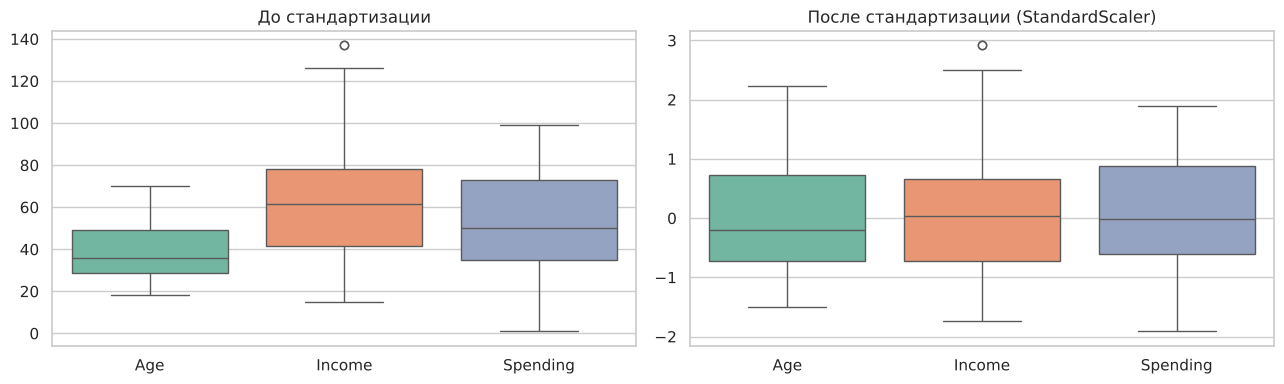

In [7]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])           # стандартизация: z = (x − μ) / σ
Xdf = pd.DataFrame(X, columns=FEATURES)

before = df[FEATURES].agg(["mean", "std", "min", "max"]).T
after = Xdf.agg(["mean", "std", "min", "max"]).T
display(pd.concat({"до": before, "после": after}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df[FEATURES], ax=axes[0], palette="Set2"); axes[0].set_title("До стандартизации")
sns.boxplot(data=Xdf, ax=axes[1], palette="Set2"); axes[1].set_title("После стандартизации (StandardScaler)")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Применяем `StandardScaler`: каждый признак преобразуется как z = (x − μ)/σ, после чего среднее равно 0, а стандартное отклонение — 1. Таблица сравнивает статистику до и после, диаграммы «ящик с усами» показывают масштабы признаков.

**Вывод.** До стандартизации признаки имеют разные диапазоны (возраст 18–70, доход 15–137, траты 1–99), и доход вносил бы наибольший вклад в евклидово расстояние. После преобразования все признаки центрированы (среднее ≈ 0) и имеют единичный разброс (σ = 1.0025 — это поправка `ddof=0` в `StandardScaler` против `ddof=1` в `pandas`), диапазон примерно −1.9…2.9. **Обоснование выбора:** (1) K-means и метод Уорда основаны на евклидовом расстоянии и минимизации суммы квадратов, поэтому чувствительны к масштабу — требуется выравнивание дисперсий (так же рекомендует задание); (2) признаки близки к симметричным и выбросов нет, поэтому стандартизация не искажает форму распределений; (3) при min–max нормализации масштаб задавался бы только крайними значениями (например, доходом 137), и основная масса данных оказалась бы сжата, а в `StandardScaler` масштаб определяется разбросом всей выборки. Далее все алгоритмы работают с матрицей `X` — стандартизованными признаками.

## 4. Структура данных: диаграммы рассеивания и выбор методов

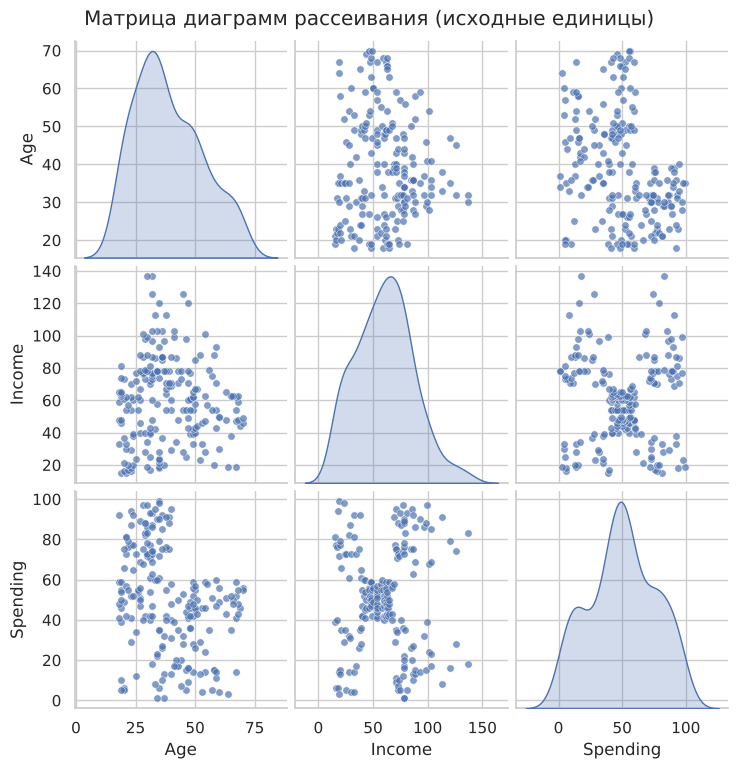

In [8]:
g = sns.pairplot(df[FEATURES], diag_kind="kde", corner=False, plot_kws={"s": 28, "alpha": 0.7, "color": "#4C72B0"},
                 diag_kws={"color": "#4C72B0"})
g.fig.suptitle("Матрица диаграмм рассеивания (исходные единицы)", y=1.02)
plt.show()

**Пояснение к блоку кода.** Строим матрицу диаграмм рассеивания (`pairplot`): на диагонали — оценки плотности каждого признака, вне диагонали — диаграммы для каждой пары признаков. Цель — визуально оценить предполагаемое число кластеров, их форму, размер и плотность.

**Вывод по графикам.** Наиболее информативна диаграмма `Income`–`Spending`: на ней отчётливо видны **пять компактных «облаков»** — центральное (доход 40–70, траты 40–60), которое самое плотное, и четыре по углам (низкий доход — низкие траты, низкий доход — высокие траты, высокий доход — низкие траты, высокий доход — высокие траты), где точки расположены реже. Диаграммы с возрастом (`Age`–`Spending`, `Age`–`Income`) показывают дополнительную структуру: высокие траты (> 60) характерны почти только для клиентов моложе 40 лет, а клиенты старше 40 лет почти всегда тратят умеренно или мало; центральное облако при учёте возраста естественно распадается на «молодых» и «возрастных» клиентов. Поэтому в трёхмерном пространстве ожидается **5–6 кластеров** (5 — по доходу и тратам, 6 — с учётом возраста). Облака имеют округлую (близкую к сферической) форму, примерно одинаковый масштаб и не вытянуты и не вложены друг в друга; между соседними группами нет пустых промежутков, т.е. разделены они умеренно.

**Аргументация выбора методов.** Исходя из формы, размера и плотности групп выбраны:

- **K-means** — подходит для компактных, выпуклых, округлых кластеров сопоставимого размера; быстрый, даёт интерпретируемые центры; кластеры по форме близки к предположению метода;
- **иерархическая агломеративная кластеризация (метод Уорда)** — тоже минимизирует внутрикластерную дисперсию (для сферических групп близка к K-means по критерию), но не зависит от случайной инициализации, даёт дендрограмму, по которой независимо от K-means можно оценить число кластеров; выбор двух методов с единым критерием, но разным алгоритмом, позволяет проверить устойчивость результата.

Не выбраны: **DBSCAN** — группы не разделены областями низкой плотности (соприкасаются), а плотность разная (центральное облако плотнее угловых), поэтому один параметр ε либо слил бы соседние группы, либо отнёс разреженные облака к шуму; **EM-алгоритм (GMM)** — по сути, подходит, но при 200 объектах оценка полных ковариационных матриц ненадёжна, а для округлых групп результат будет близок к K-means.

## 5. Подбор числа кластеров

Локоть (по хорде): k = 4;  максимум silhouette K-means: k = 6;  максимум silhouette Ward: k = 6
Максимум Calinski–Harabasz K-means: k = 6;  минимум Davies–Bouldin K-means: k = 7


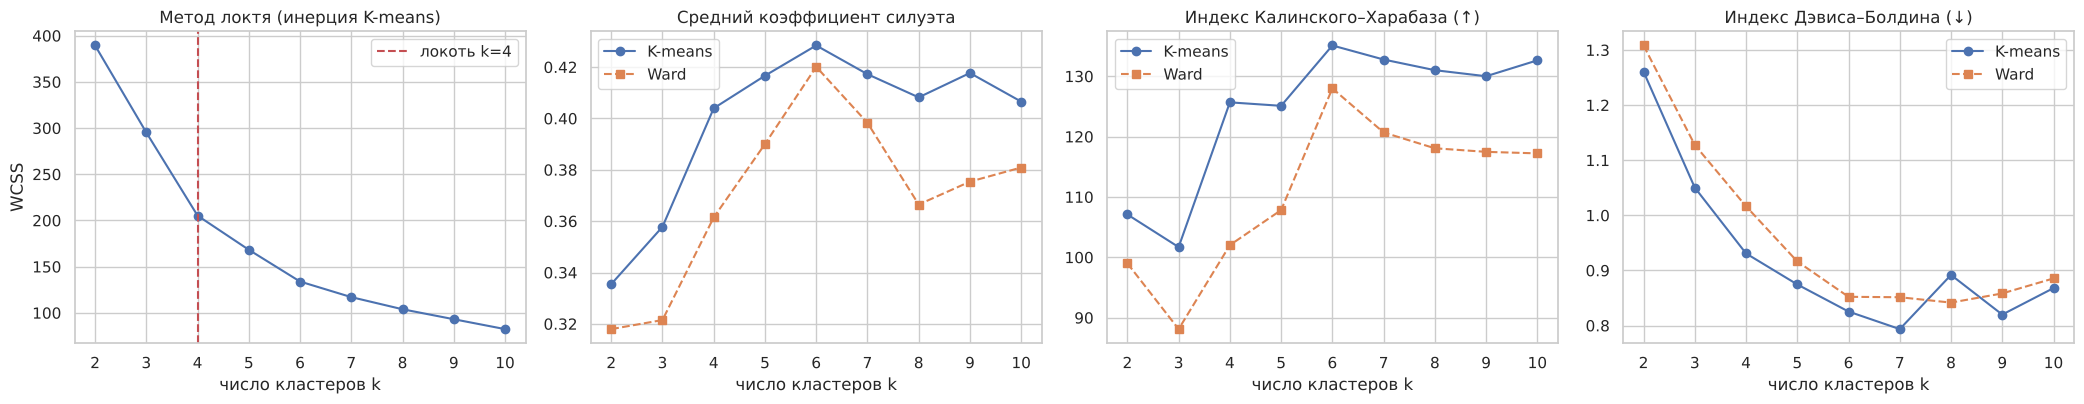

,inertia (K-means),silhouette K-means,CH K-means,DB K-means,silhouette Ward,CH Ward,DB Ward
k,,,,,,,
2,389.3862,0.3355,107.0956,1.2607,0.3180,99.0007,1.3083
3,295.2122,0.3578,101.6949,1.0503,0.3215,88.1017,1.1277
4,205.2251,0.4040,125.6764,0.9308,0.3615,102.0194,1.0164
5,168.2476,0.4166,125.1009,0.8746,0.3900,107.8266,0.9163
6,133.8684,0.4284,135.1021,0.8254,0.4201,127.9865,0.8521
7,117.0116,0.4172,132.7743,0.7935,0.3983,120.6868,0.8513
8,103.8733,0.4082,131.0062,0.8918,0.3665,118.0668,0.8416
9,93.0929,0.4177,130.0036,0.8198,0.3754,117.4751,0.8582
10,82.3852,0.4066,132.6383,0.8679,0.3809,117.2219,0.8855


In [9]:
KS = list(range(2, 11))
rows = []
for k in KS:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X)
    rows.append({"k": k, "inertia (K-means)": km.inertia_,
                 "silhouette K-means": silhouette_score(X, km.labels_),
                 "CH K-means": calinski_harabasz_score(X, km.labels_),
                 "DB K-means": davies_bouldin_score(X, km.labels_),
                 "silhouette Ward": silhouette_score(X, ag.labels_),
                 "CH Ward": calinski_harabasz_score(X, ag.labels_),
                 "DB Ward": davies_bouldin_score(X, ag.labels_)})
sel = pd.DataFrame(rows).set_index("k")

# «локоть» по максимальному расстоянию от точки кривой до хорды, соединяющей концы кривой
def elbow_k(ks, y):
    ks, y = np.asarray(ks, float), np.asarray(y, float)
    p1, p2 = np.array([ks[0], y[0]]), np.array([ks[-1], y[-1]])
    v = (p2 - p1) / np.linalg.norm(p2 - p1)
    pts = np.c_[ks, y] - p1
    dist = np.abs(pts[:, 0] * v[1] - pts[:, 1] * v[0])
    return int(ks[np.argmax(dist)]), dist

K_ELBOW, elbow_dist = elbow_k(KS, sel["inertia (K-means)"])
K_KM = int(sel["silhouette K-means"].idxmax())
K_HC = int(sel["silhouette Ward"].idxmax())
print(f"Локоть (по хорде): k = {K_ELBOW};  максимум silhouette K-means: k = {K_KM};  максимум silhouette Ward: k = {K_HC}")
print(f"Максимум Calinski–Harabasz K-means: k = {int(sel['CH K-means'].idxmax())};  минимум Davies–Bouldin K-means: k = {int(sel['DB K-means'].idxmin())}")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
axes[0].plot(KS, sel["inertia (K-means)"], "o-", color="#4C72B0"); axes[0].axvline(K_ELBOW, color="#C44E52", ls="--", label=f"локоть k={K_ELBOW}")
axes[0].set_title("Метод локтя (инерция K-means)"); axes[0].set_ylabel("WCSS"); axes[0].legend()
axes[1].plot(KS, sel["silhouette K-means"], "o-", label="K-means"); axes[1].plot(KS, sel["silhouette Ward"], "s--", label="Ward")
axes[1].set_title("Средний коэффициент силуэта"); axes[1].legend()
axes[2].plot(KS, sel["CH K-means"], "o-", label="K-means"); axes[2].plot(KS, sel["CH Ward"], "s--", label="Ward")
axes[2].set_title("Индекс Калинского–Харабаза (↑)"); axes[2].legend()
axes[3].plot(KS, sel["DB K-means"], "o-", label="K-means"); axes[3].plot(KS, sel["DB Ward"], "s--", label="Ward")
axes[3].set_title("Индекс Дэвиса–Болдина (↓)"); axes[3].legend()
for ax in axes: ax.set_xlabel("число кластеров k"); ax.set_xticks(KS)
plt.tight_layout(); plt.show()
sel

**Пояснение к блоку кода.** Для *k* = 2…10 обучаем K-means (`n_init=10`) и иерархическую кластеризацию (Уорд) и считаем: инерцию (WCSS) для метода локтя, средний коэффициент силуэта, индекс Калинского–Харабаза (CH, чем больше, тем лучше) и индекс Дэвиса–Болдина (DB, чем меньше, тем лучше). «Локоть» определяется автоматически как точка кривой инерции, наиболее удалённая от хорды, соединяющей её концы.

**Вывод по графикам и таблице.** Кривая инерции убывает плавно, чёткого «излома» нет; автоматический критерий указывает *k* = 4, но глядя на график видно, что скорость падения заметно замедляется после *k* = 5–6, поэтому **метод локтя неоднозначен** и даёт диапазон 4–6. Средний силуэт K-means максимален при **k = 6** (0.428), при *k* = 5, 7 и 9 он почти такой же (0.417–0.418), т.е. разница между этими значениями невелика; для метода Уорда максимум также при *k* = 6 (0.420), другие *k* заметно хуже (0.399 при 7, 0.390 при 5). Индекс Калинского–Харабаза у обоих методов максимален при *k* = 6 (135.1 для K-means и 128.0 для Уорда). Индекс Дэвиса–Болдина продолжает улучшаться до *k* = 7 (0.794; при *k* = 6 — 0.825) для K-means и практически не меняется при *k* = 6–8 (0.842–0.852) у Уорда, поэтому он не противоречит выбору *k* = 6. Итог: по силуэту и CH оптимально **k = 6** для обоих методов; значения *k* = 5 (естественное для пары `Income`–`Spending`) и 7 — ближайшие альтернативы.

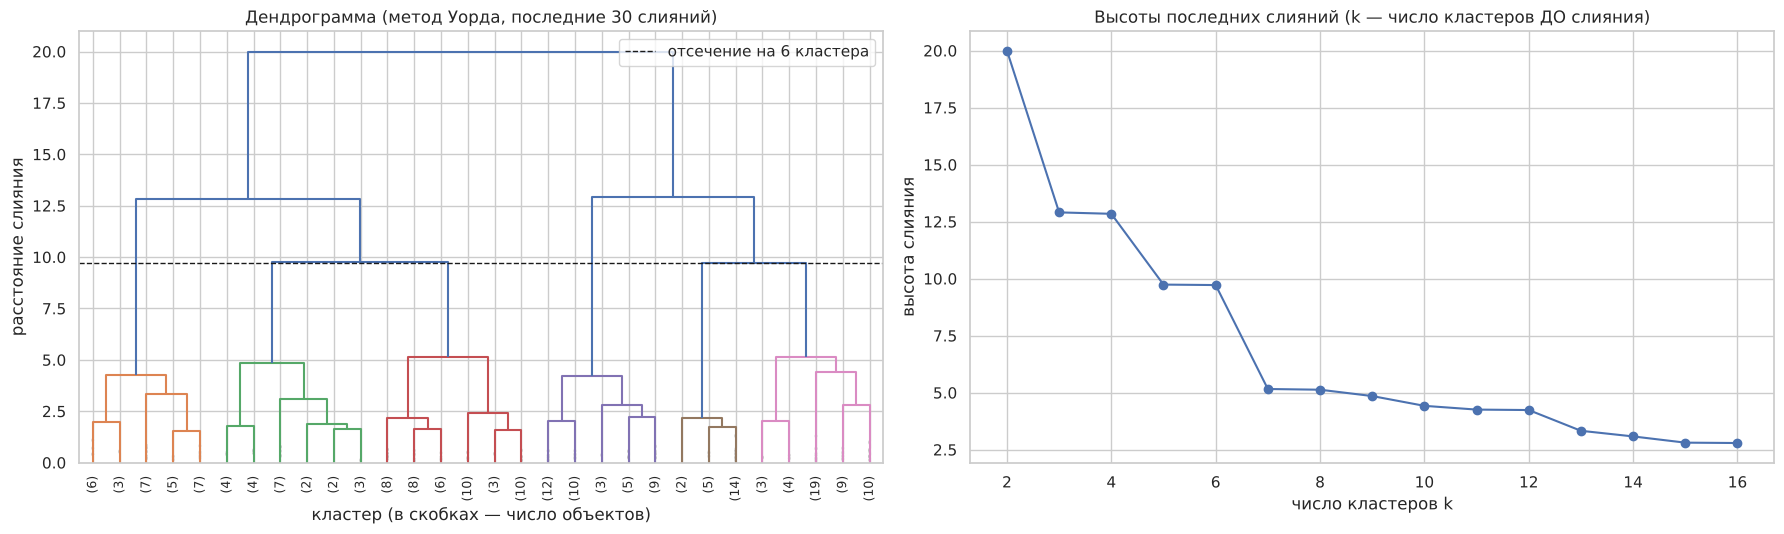

k,2,3,4,5,6,7,8,9,10,11
высота слияния k→k−1,20.0000,12.9060,12.8438,9.7392,9.7190,5.1604,5.1291,4.8512,4.4221,4.2575
запас по высоте для k кластеров,7.0941,0.0622,3.1046,0.0202,4.5586,0.0314,0.2779,0.4291,0.1647,NaN


In [10]:
Z = linkage(X, method="ward")
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True,
           color_threshold=Z[-(K_HC - 1), 2] - 1e-9, ax=axes[0])
axes[0].axhline(Z[-(K_HC - 1), 2] - 1e-9, color="k", ls="--", lw=1, label=f"отсечение на {K_HC} кластера")
axes[0].set_title("Дендрограмма (метод Уорда, последние 30 слияний)"); axes[0].set_xlabel("кластер (в скобках — число объектов)")
axes[0].set_ylabel("расстояние слияния"); axes[0].legend()

heights = Z[:, 2][::-1][:15]                       # высоты 15 последних слияний
axes[1].plot(range(2, 2 + len(heights)), heights, "o-", color="#4C72B0")
axes[1].set_title("Высоты последних слияний (k — число кластеров ДО слияния)")
axes[1].set_xlabel("число кластеров k"); axes[1].set_ylabel("высота слияния")
plt.tight_layout(); plt.show()

gap = pd.DataFrame({"k": range(2, 12), "высота слияния k→k−1": heights[:10]}).set_index("k")
gap["запас по высоте для k кластеров"] = gap["высота слияния k→k−1"] - gap["высота слияния k→k−1"].shift(-1)   # на сколько можно сдвинуть порог, не меняя разбиение на k кластеров
gap.T

**Пояснение к блоку кода.** Строим дендрограмму метода Уорда (показаны последние 30 слияний; в скобках — число объектов в «свёрнутой» ветви) и график высот слияний. Число кластеров определяется по самому длинному интервалу высот, в котором разбиение не меняется: для *k* кластеров порог можно двигать между высотой слияния (*k*+1 → *k*) и высотой слияния (*k* → *k*−1); таблица показывает размер такого «запаса».

**Вывод по графикам.** Самый большой запас по высоте у *k* = 2 (≈ 7.1): две крупные ветви — молодые клиенты с повышенными тратами (105 человек, средний возраст ≈ 29, траты ≈ 66) и более возрастные с пониженными тратами (95 человек, ≈ 50 лет, траты ≈ 32). Далее по величине запаса следует **k = 6** (≈ 4.6): слияния 6 → 5 и 5 → 4 происходят на близких высотах (≈ 9.7), а при переходе к 7 кластерам высота резко падает до ≈ 5.2 — на графике видно «колено» в точке *k* = 6. Запас при *k* = 4 заметно меньше (≈ 3.1), при *k* = 3 и *k* = 5 — практически нулевой (≈ 0.06 и 0.02), то есть эти разбиения неустойчивы. Двухкластерное разбиение слишком грубо для сегментации клиентов (силуэт 0.32), поэтому дендрограмма подтверждает **k = 6**.

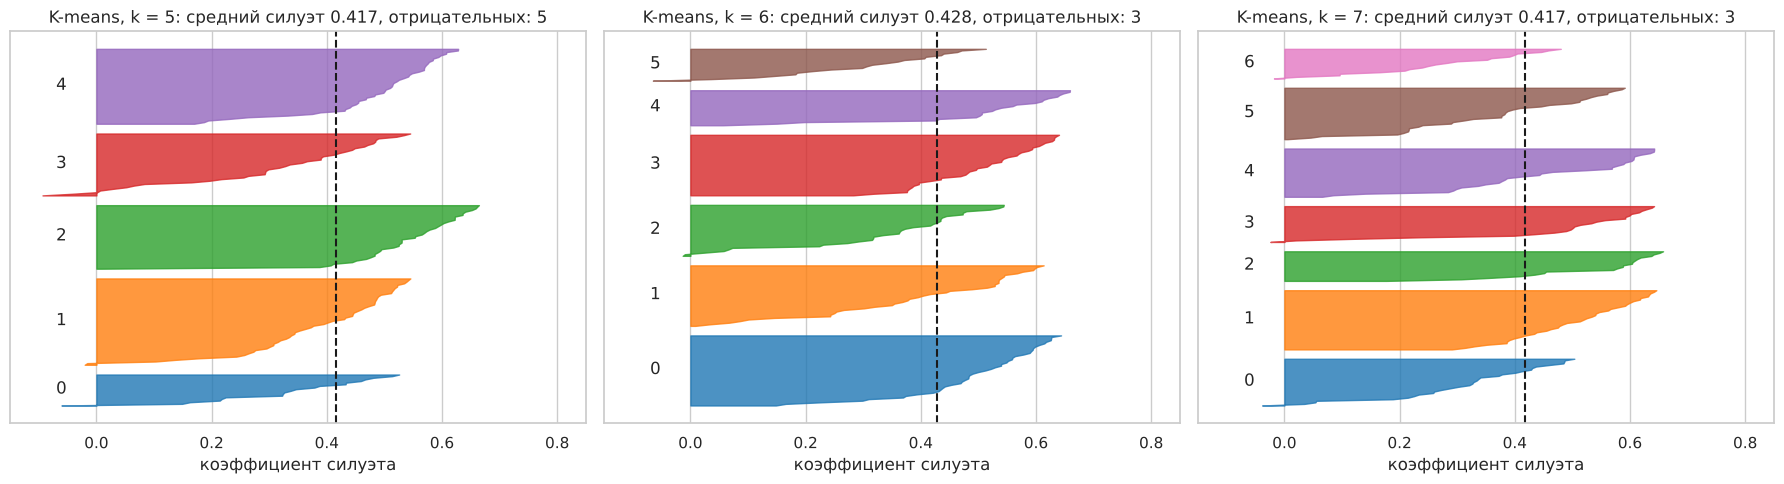

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [K_KM - 1, K_KM, K_KM + 1]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    s = silhouette_samples(X, lab); y0 = 5
    for c in range(k):
        sc = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.8, color=plt.cm.tab10(c))
        ax.text(-0.07, y0 + len(sc) / 2, str(c), va="center"); y0 += len(sc) + 5
    ax.axvline(s.mean(), color="k", ls="--"); ax.set_xlim(-0.15, 0.85)
    ax.set_title(f"K-means, k = {k}: средний силуэт {s.mean():.3f}, отрицательных: {(s < 0).sum()}")
    ax.set_xlabel("коэффициент силуэта"); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Для *k* = 5, 6, 7 строим силуэтные диаграммы K-means: для каждого объекта вычислен коэффициент силуэта *s* = (*b* − *a*)/max(*a*, *b*), где *a* — среднее расстояние до своего кластера, *b* — до ближайшего чужого; объекты сгруппированы по кластерам и отсортированы. Пунктир — средний силуэт.

**Вывод.** При *k* = 6 средний силуэт 0.428 (наибольший), отрицательных значений (объектов, вероятно попавших «не в свой» кластер) всего 3, средние силуэты кластеров лежат в диапазоне 0.29–0.51, толщина «лопастей» (размеры кластеров) сбалансирована. При *k* = 5 отрицательных значений уже 5 (средние силуэты кластеров 0.30–0.54), при *k* = 7 естественные группы начинают дробиться (появляется кластер со средним силуэтом 0.27). Выбираем **k = 6 для обоих методов** (то же значение даёт и автоматический выбор в коде).

## 6. Кластеризация двумя методами

In [12]:
km = KMeans(n_clusters=K_KM, n_init=10, random_state=SEED).fit(X)
hc = AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit(X)

# Для удобства сравнения нумеруем кластеры по возрастанию среднего дохода (метки алгоритмов произвольны)
def relabel(labels, ref=df["Income"].values):
    order = pd.Series(ref).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order)}
    return np.vectorize(mapping.get)(labels)

lab_km = relabel(km.labels_)
lab_hc = relabel(hc.labels_)
df["KMeans"], df["Ward"] = lab_km, lab_hc
print(f"K-means: k = {K_KM}, итераций до сходимости: {km.n_iter_}, инерция = {km.inertia_:.2f}")
print(f"Иерархическая (Уорд): k = {K_HC}")
print("Размеры кластеров K-means:", np.bincount(lab_km).tolist())
print("Размеры кластеров Ward:   ", np.bincount(lab_hc).tolist())

K-means: k = 6, итераций до сходимости: 6, инерция = 133.87
Иерархическая (Уорд): k = 6
Размеры кластеров K-means: [23, 21, 45, 39, 39, 33]
Размеры кластеров Ward:    [21, 22, 45, 45, 39, 28]


**Пояснение к блоку кода.** Обучаем **K-means** (`KMeans`, *k* = 6, `n_init=10` — десять случайных инициализаций, берётся лучшая по инерции, чтобы не попасть в локальный минимум) и **иерархическую агломеративную кластеризацию** (`AgglomerativeClustering`, *k* = 6, `linkage="ward"`). Метки кластеров, которые алгоритмы присваивают произвольно, перенумерованы в порядке возрастания среднего дохода — так кластеры двух методов удобно сопоставлять.

**Вывод.** K-means сошёлся за 6 итераций, итоговая инерция 133.87. Размеры кластеров K-means: 23, 21, 45, 39, 39, 33; Уорда: 21, 22, 45, 45, 39, 28. Кластеры сбалансированы (от 10.5% до 22.5% выборки), вырожденных кластеров нет, размеры двух методов близки.

## 7. Метрики качества, расстояния и компактность кластеров

In [13]:
def dunn_index(X, labels):
    cl = np.unique(labels)
    diam = max(pdist(X[labels == c]).max() if (labels == c).sum() > 1 else 0 for c in cl)
    sep = min(cdist(X[labels == a], X[labels == b]).min() for i, a in enumerate(cl) for b in cl[i + 1:])
    return sep / diam

def quality(X, labels):
    cl = np.unique(labels)
    cent = np.array([X[labels == c].mean(0) for c in cl])
    d_to_c = np.linalg.norm(X - cent[np.searchsorted(cl, labels)], axis=1)       # расстояние до своего центра
    cd = squareform(pdist(cent))
    return {"Silhouette (↑)": silhouette_score(X, labels),
            "Calinski–Harabasz (↑)": calinski_harabasz_score(X, labels),
            "Davies–Bouldin (↓)": davies_bouldin_score(X, labels),
            "Dunn (↑)": dunn_index(X, labels),
            "WCSS — сумма кв. расстояний до центров (↓)": float((d_to_c ** 2).sum()),
            "ср. расстояние до центра кластера": float(d_to_c.mean()),
            "ср. попарное расстояние внутри кластеров": float(np.mean(np.concatenate([pdist(X[labels == c]) for c in cl if (labels == c).sum() > 1]))),
            "мин. расстояние между центрами": float(cd[np.triu_indices(len(cl), 1)].min()),
            "ср. расстояние между центрами": float(cd[np.triu_indices(len(cl), 1)].mean())}

qual = pd.DataFrame({"K-means": quality(X, lab_km), "Ward": quality(X, lab_hc)})
qual

,K-means,Ward
Silhouette (↑),0.4284,0.4201
Calinski–Harabasz (↑),135.1021,127.9865
Davies–Bouldin (↓),0.8254,0.8521
Dunn (↑),0.0621,0.0718
WCSS — сумма кв. расстояний до центров (↓),133.8684,139.5797
ср. расстояние до центра кластера,0.7417,0.7578
ср. попарное расстояние внутри кластеров,1.0336,1.0612
мин. расстояние между центрами,1.6744,1.7916
ср. расстояние между центрами,2.3974,2.4284


**Пояснение к блоку кода.** Для обоих разбиений рассчитаны **внутренние метрики** (эталонных меток нет): силуэт (↑), индекс Калинского–Харабаза (↑), индекс Дэвиса–Болдина (↓), индекс Данна (↑; отношение минимального расстояния между точками разных кластеров к максимальному диаметру кластера); **компактность** — сумма квадратов расстояний до центров (WCSS), среднее расстояние до центра своего кластера и среднее попарное расстояние внутри кластеров; **разделённость** — минимальное и среднее расстояние между центрами кластеров. Все расстояния евклидовы, в единицах стандартизованных признаков.

**Вывод.** По силуэту (0.428 против 0.420), индексу CH (135.1 против 128.0), DB (0.825 против 0.852) и WCSS (133.9 против 139.6) K-means немного лучше, что естественно: он напрямую оптимизирует WCSS. Силуэт ≈ 0.43 означает **умеренную** кластерную структуру: кластеры реальны, но соседние группы частично примыкают друг к другу (согласуется со статистикой Хопкинса 0.69 и диаграммами рассеивания). Среднее расстояние объекта до центра своего кластера 0.74–0.76 при минимальном расстоянии между центрами 1.67–1.79, т.е. центры разнесены примерно в 2.2–2.4 раза дальше, чем «радиус» кластера — кластеры компактны и различимы, но не изолированы. Индекс Данна мал (0.062 и 0.072; у Уорда немного выше): он определяется лишь одной ближайшей парой точек из разных кластеров и самым «широким» кластером, поэтому при соприкасающихся группах закономерно близок к нулю, и его не следует использовать как основной критерий. Различия между методами по основным метрикам небольшие (2–5%) — качество разбиений практически одинаково.

K-means — компактность кластеров (стандартизованные признаки):


,размер,"доля, %",ср. расст. до центра,макс. расст. до центра,диаметр,ср. силуэт
кластер,,,,,,
0,23,11.5000,0.6070,1.6079,2.6014,0.5075
1,21,10.5000,0.9070,1.9440,3.3892,0.2942
2,45,22.5000,0.6952,1.0909,1.9531,0.4909
3,39,19.5000,0.6813,1.7088,2.5390,0.3873
4,39,19.5000,0.6872,1.9361,2.6927,0.5052
5,33,16.5000,0.9296,1.9687,3.1898,0.3313


Ward — компактность кластеров:


,размер,"доля, %",ср. расст. до центра,макс. расст. до центра,диаметр,ср. силуэт
кластер,,,,,,
0,21,10.5000,0.5426,1.0626,1.7170,0.5987
1,22,11.0000,0.9608,1.9998,3.5822,0.2574
2,45,22.5000,0.7100,1.2463,2.3087,0.4776
3,45,22.5000,0.8070,1.9182,3.1839,0.2741
4,39,19.5000,0.6872,1.9361,2.6927,0.5252
5,28,14.0000,0.8555,1.9431,3.1898,0.4100


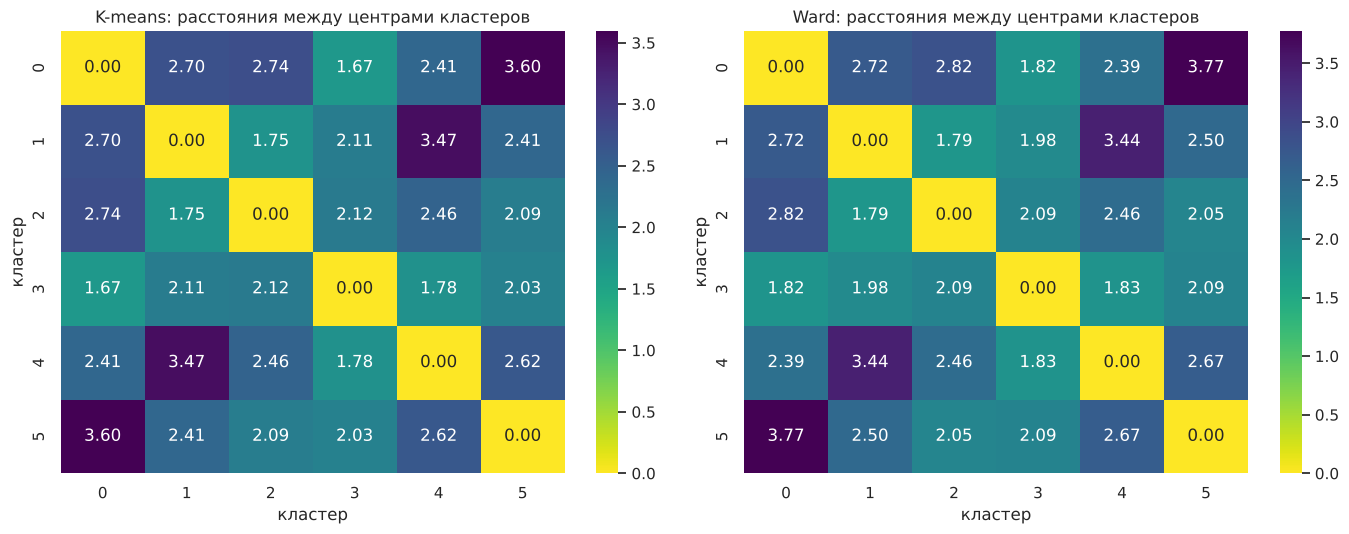

In [14]:
def per_cluster(X, labels):
    rows = []
    s = silhouette_samples(X, labels)
    for c in np.unique(labels):
        P = X[labels == c]; mu = P.mean(0)
        d = np.linalg.norm(P - mu, axis=1)
        rows.append({"кластер": c, "размер": len(P), "доля, %": len(P) / len(X) * 100,
                     "ср. расст. до центра": d.mean(), "макс. расст. до центра": d.max(),
                     "диаметр": pdist(P).max(), "ср. силуэт": s[labels == c].mean()})
    return pd.DataFrame(rows).set_index("кластер")

print("K-means — компактность кластеров (стандартизованные признаки):")
display(per_cluster(X, lab_km))
print("Ward — компактность кластеров:")
display(per_cluster(X, lab_hc))

def centroid_dist(labels):
    cl = np.unique(labels); cent = np.array([X[labels == c].mean(0) for c in cl])
    return pd.DataFrame(squareform(pdist(cent)), index=cl, columns=cl)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    sns.heatmap(centroid_dist(lab), annot=True, fmt=".2f", cmap="viridis_r", ax=ax)
    ax.set_title(f"{name}: расстояния между центрами кластеров"); ax.set_xlabel("кластер"); ax.set_ylabel("кластер")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Для каждого кластера считаются размер, доля, среднее и максимальное расстояние до центра, диаметр (наибольшее попарное расстояние) и средний силуэт — это характеристики компактности. Тепловые карты показывают матрицы расстояний между центрами кластеров (чем светлее, тем ближе; в палитре `viridis_r`).

**Вывод.** *K-means:* самый компактный — кластер 0 (молодые клиенты с низким доходом и высокими тратами: среднее расстояние до центра 0.61, силуэт 0.51); кластеры 4 и 2 также плотные (силуэт 0.51 и 0.49); наименее компактны кластеры 1 и 5 (0.91 и 0.93, силуэт 0.29 и 0.33) — это группы с низкими тратами, более «размазанные» по возрасту. *Ward:* самый плотный — кластер 0 (0.54, силуэт 0.60), самые размытые — кластеры 1 и 3 (0.96 и 0.81; силуэт 0.26 и 0.27). По расстояниям между центрами (K-means): ближе всего расположены кластеры 0–3 (1.67), 1–2 (1.75) и 3–4 (1.78) — эти пары граничат и более вероятны для «перетекания» объектов; дальше всего — 0–5 (3.60) и 1–4 (3.47), т.е. диаметрально противоположные сегменты («молодые, малообеспеченные, но тратящие» и «обеспеченные, но экономные»; «малообеспеченные экономные» и «обеспеченные тратящие»). Для Ward картина практически та же (минимум 1.79–1.82, максимум 3.77).

**Внешние метрики.** Истинное разбиение на классы в данных неизвестно, поэтому они рассчитаны в блоке сравнения методов (раздел 11): для согласованности двух разбиений и для проверки связи кластеров с полом клиентов.

## 8. Центры кластеров и интерпретация

K-means — центры кластеров (в исходных единицах):


,размер,Age,Income,Spending,"доля женщин, %"
0,23,25.0000,25.2609,77.6087,56.5217
1,21,45.5238,26.2857,19.3810,61.9048
2,45,56.3333,54.2667,49.0667,57.7778
3,39,26.7949,57.1026,48.1282,64.1026
4,39,32.6923,86.5385,82.1282,53.8462
5,33,41.9394,88.9394,16.9697,42.4242


Ward — средние значения по кластерам (в исходных единицах):


,размер,Age,Income,Spending,"доля женщин, %"
0,21,24.8095,25.6190,80.2381,61.9048
1,22,44.3182,25.7727,20.2727,59.0909
2,45,56.4000,55.2889,48.3556,53.3333
3,45,27.3778,57.5111,45.8444,60.0000
4,39,32.6923,86.5385,82.1282,53.8462
5,28,43.8929,91.2857,16.6786,50.0000


Макс. расхождение центров sklearn и средних по кластерам: 1.4210854715202004e-14


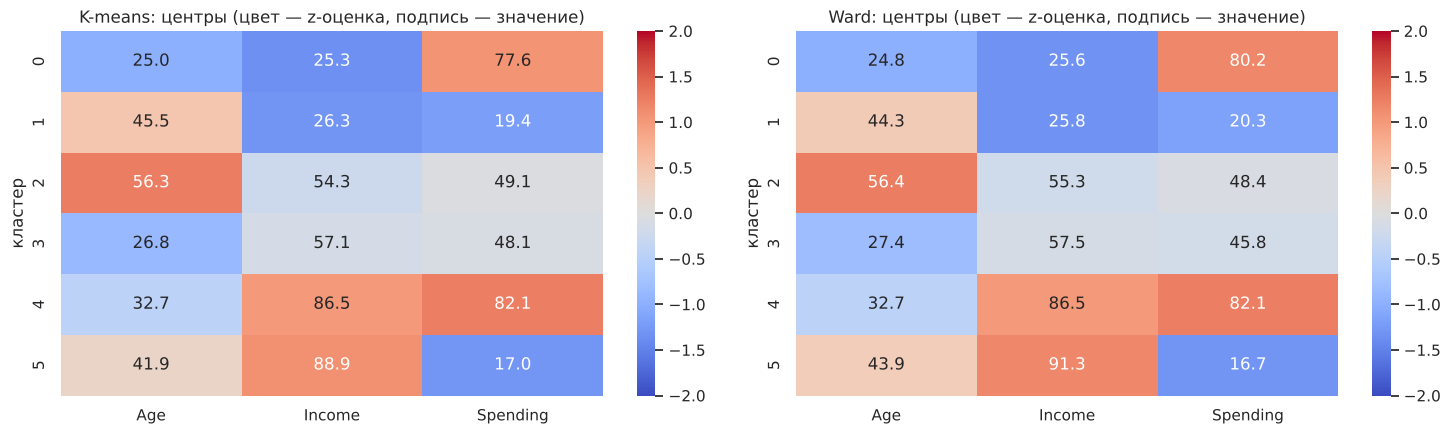

In [15]:
def profile(labels):
    g = df.groupby(labels)
    out = g[FEATURES].mean()
    out.insert(0, "размер", g.size())
    out["доля женщин, %"] = g["Gender"].apply(lambda s: (s == "Female").mean() * 100)
    return out

print("K-means — центры кластеров (в исходных единицах):")
prof_km = profile(lab_km); display(prof_km)
print("Ward — средние значения по кластерам (в исходных единицах):")
prof_hc = profile(lab_hc); display(prof_hc)

# центры K-means: проверка, что inverse_transform центров совпадает со средними по кластерам
centers_orig = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=FEATURES)
centers_orig.index = [pd.Series(lab_km)[km.labels_ == i].iloc[0] for i in range(K_KM)]
centers_orig = centers_orig.sort_index()
print("Макс. расхождение центров sklearn и средних по кластерам:", float(np.abs(centers_orig.values - prof_km[FEATURES].values).max()))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, p, name in zip(axes, [prof_km, prof_hc], ["K-means", "Ward"]):
    z = (p[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
    sns.heatmap(z, annot=p[FEATURES].round(1), fmt="", cmap="coolwarm", center=0, vmin=-2, vmax=2, ax=ax)
    ax.set_title(f"{name}: центры (цвет — z-оценка, подпись — значение)"); ax.set_ylabel("кластер")
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Таблицы показывают центры кластеров K-means (возвращены в исходные единицы с помощью `scaler.inverse_transform`) и средние значения по кластерам Уорда (у иерархического метода центров нет — используются средние), плюс размер кластера и долю женщин. Проверка: центры sklearn совпадают со средними по кластерам (расхождение ≈ 10⁻¹⁴). Тепловые карты: цвет — стандартизованное отклонение от среднего по выборке (красное — выше, синее — ниже), подпись — значение в исходных единицах.

**Вывод — содержательная интерпретация групп (по K-means).**

| Кластер | Размер | Возраст | Доход, тыс. $ | Траты | Описание сегмента |
|---|---|---|---|---|---|
| 0 | 23 | ≈ 25 | ≈ 25 | ≈ 78 | **«Молодые транжиры»**: молодёжь с низким доходом, но высокой активностью покупок; чувствительна к акциям, скидкам, модным товарам |
| 1 | 21 | ≈ 46 | ≈ 26 | ≈ 19 | **«Экономные с низким доходом»**: зрелые клиенты, тратят мало, ограничены бюджетом; низкий приоритет для маркетинга |
| 2 | 45 | ≈ 56 | ≈ 54 | ≈ 49 | **«Возрастные середняки»**: старший возраст, средний доход и умеренные траты; стабильные покупатели |
| 3 | 39 | ≈ 27 | ≈ 57 | ≈ 48 | **«Молодые середняки»**: молодые клиенты со средним доходом и умеренными тратами; потенциал роста трат |
| 4 | 39 | ≈ 33 | ≈ 87 | ≈ 82 | **«Целевая аудитория»**: высокий доход и высокие траты, самый ценный сегмент, нужны премиальные предложения и программа лояльности |
| 5 | 33 | ≈ 42 | ≈ 89 | ≈ 17 | **«Богатые экономные»**: высокий доход при низких тратах; неудовлетворённый спрос — самый перспективный сегмент для привлечения (персональные предложения, премиальный ассортимент) |

Разбиение по доходу и тратам образует пять «пространственных» групп (0, 1, 4, 5 — по углам, а центральная группа делится по возрасту на кластеры 2 и 3 — именно поэтому оптимальное число кластеров получилось 6, а не 5). Доля женщин во всех кластерах близка к общей (42–64%) — различия невелики и объясняются малым размером групп; пол сегментацию не определяет. Кластеры Уорда имеют практически те же профили (например, кластер 4: 33 года, 86.5 тыс., 82.1 — идентичен кластеру 4 K-means; кластеры 0, 1, 2, 3, 5 отличаются не более чем на 2–3 единицы), поэтому интерпретация сегментов не зависит от выбора метода.

## 9. Визуализация кластеров

Доля дисперсии PC1, PC2: [0.443 0.333] суммарно: 0.776


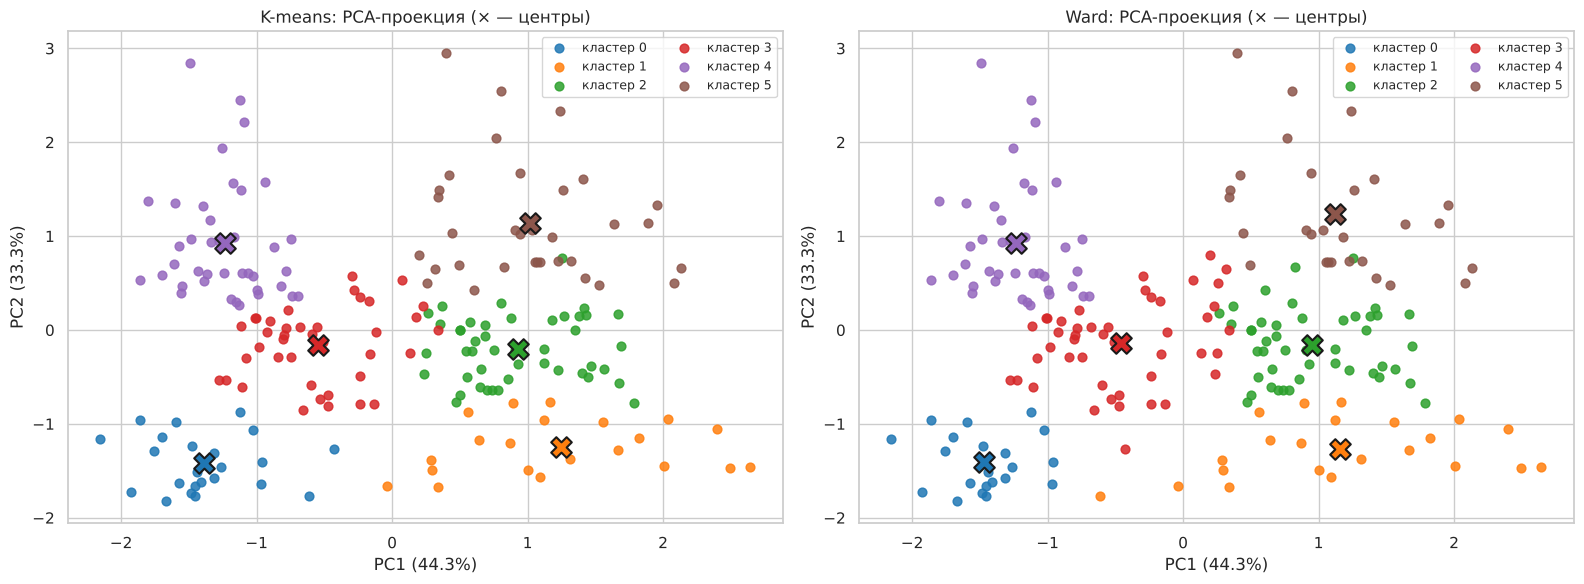

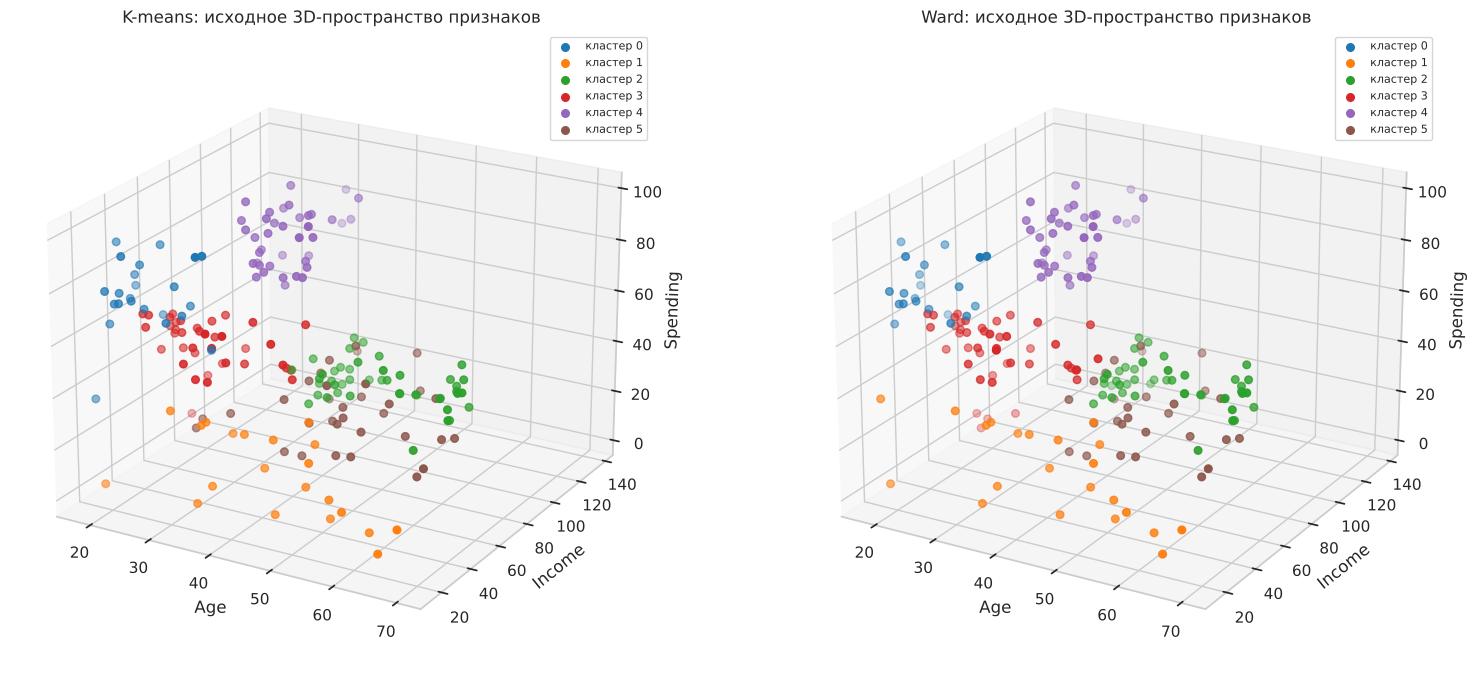

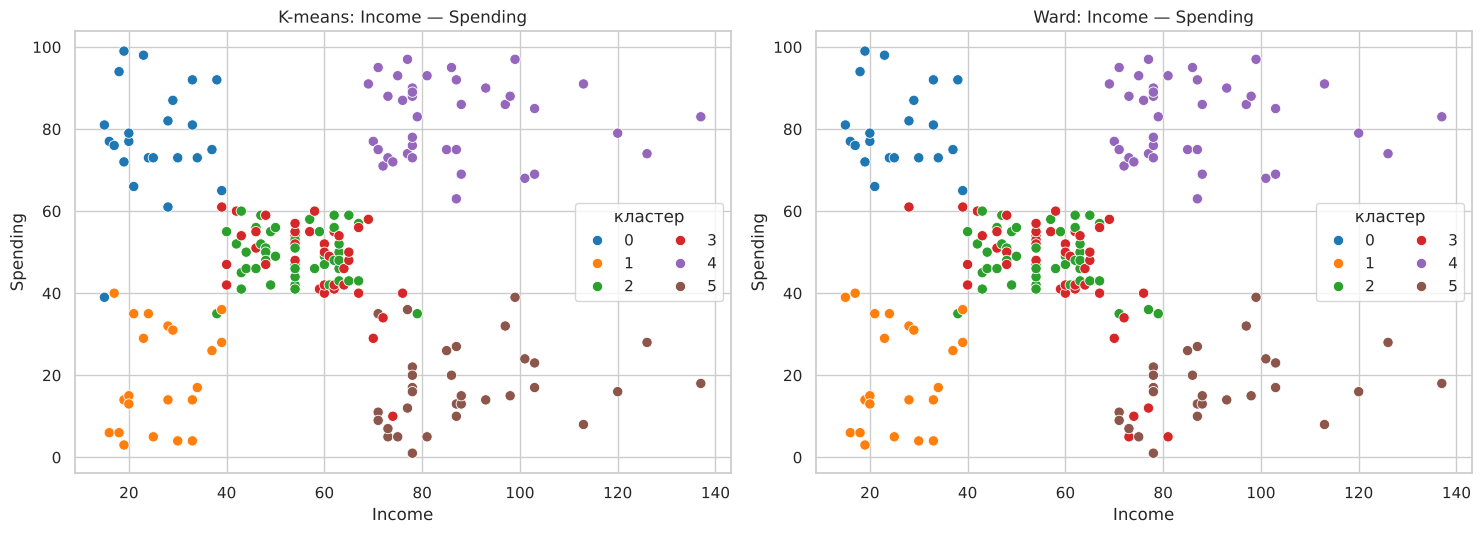

In [16]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
print("Доля дисперсии PC1, PC2:", pca.explained_variance_ratio_.round(3), "суммарно:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    for c in np.unique(lab):
        ax.scatter(P[lab == c, 0], P[lab == c, 1], s=40, color=plt.cm.tab10(c), alpha=0.85, label=f"кластер {c}")
        m = P[lab == c].mean(0)
        ax.scatter(*m, marker="X", s=220, color=plt.cm.tab10(c), edgecolor="k", linewidth=1.5)
    ax.set_title(f"{name}: PCA-проекция (× — центры)"); ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"); ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(16, 7))
for j, (lab, name) in enumerate(zip([lab_km, lab_hc], ["K-means", "Ward"])):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(df.loc[m, "Age"], df.loc[m, "Income"], df.loc[m, "Spending"], s=30, color=plt.cm.tab10(c), label=f"кластер {c}")
    ax.set_xlabel("Age"); ax.set_ylabel("Income"); ax.set_zlabel("Spending"); ax.set_title(f"{name}: исходное 3D-пространство признаков")
    ax.view_init(elev=22, azim=-60); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, lab, name in zip(axes, [lab_km, lab_hc], ["K-means", "Ward"]):
    sns.scatterplot(x=df["Income"], y=df["Spending"], hue=lab, palette="tab10", s=55, ax=ax, legend="full")
    ax.set_title(f"{name}: Income — Spending"); ax.legend(title="кластер", ncol=2)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Для визуализации в плоскости применяем PCA (две главные компоненты стандартизованных признаков); крестами показаны центры кластеров. Дополнительно строим трёхмерную диаграмму в исходных признаках и плоскость `Income`–`Spending`, раскрашенные по кластерам обоих методов.

**Вывод по графикам.** Две компоненты объясняют 77.6% дисперсии (PC1 = 44.3%, PC2 = 33.3%), поэтому проекция отражает структуру достаточно хорошо. На ней кластеры образуют шесть связных областей: по оси PC1 сегменты разделяются на «молодые и тратящие» (слева) и «старшие и менее тратящие» (справа), по оси PC2 — по доходу (сверху — высокий, снизу — низкий). Кластеры 0 (слева внизу) и 4 (слева вверху) и 5 (справа вверху) отделены хорошо, кластеры 2 и 3 в центре примыкают друг к другу, граница между ними проходит по возрасту (центры около 27 и 56 лет), расстояние между их центрами сравнительно небольшое (2.12), поэтому именно здесь возможны пограничные объекты. На плоскости `Income`–`Spending` видны пять чётких групп, а в трёх измерениях центральная группа делится на два кластера по возрасту. Визуально два метода дают почти одинаковые разбиения; различия видны лишь на границах кластеров.

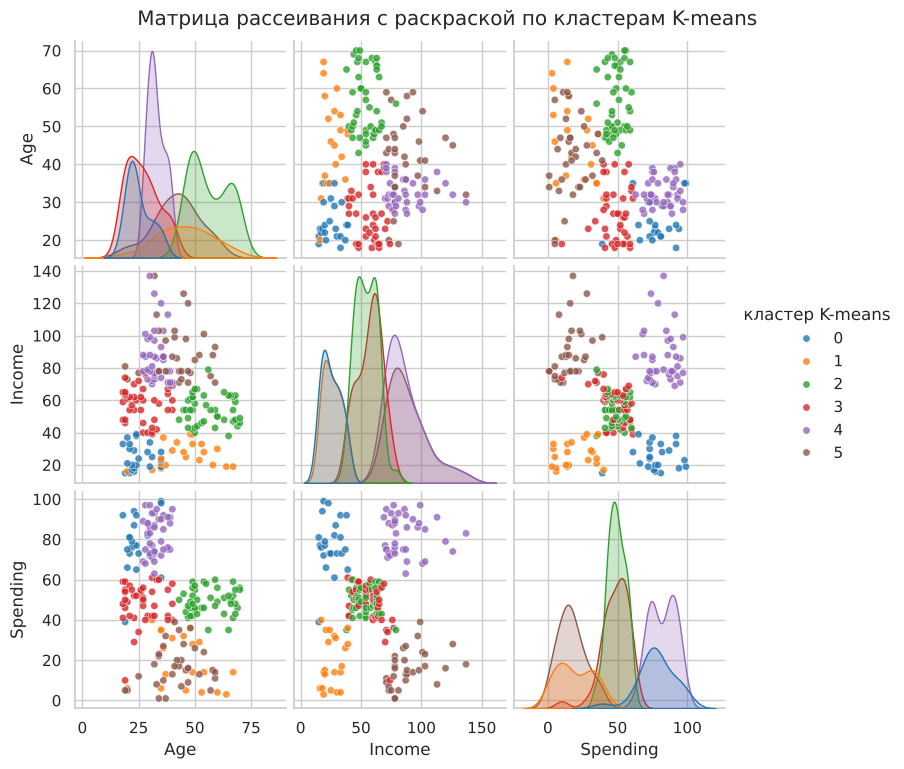

In [17]:
tmp = df[FEATURES].copy(); tmp["кластер K-means"] = lab_km
g = sns.pairplot(tmp, hue="кластер K-means", palette="tab10", diag_kind="kde", plot_kws={"s": 28, "alpha": 0.8})
g.fig.suptitle("Матрица рассеивания с раскраской по кластерам K-means", y=1.02); plt.show()

**Пояснение к блоку кода.** Матрица рассеивания в исходных признаках, раскрашенная по кластерам K-means: на диагонали — плотности признаков внутри каждого кластера.

**Вывод.** Кластеры чётко различаются по доходу и тратам, а по возрасту их распределения пересекаются, но заметно смещены: кластеры 0 и 3 — молодые, 2 и 1 — старше. Это подтверждает, что именно сочетание всех трёх признаков даёт шесть сегментов, и что возраст необходим для разделения центральной группы.

## 10. Влияние параметров и устойчивость

,ARI подвыборок (ср.),ARI подвыборок (σ),ARI между запусками n_init=1 (ср.),ARI между запусками (мин.),"inertia (n_init=1, ср.)","inertia (n_init=1, σ)"
k,,,,,,
2,0.9900,0.0177,0.9092,0.0541,396.5685,21.8122
3,0.7535,0.2583,0.6134,0.3881,300.2795,10.2121
4,0.9852,0.0215,0.8764,0.5694,219.5487,21.8948
5,0.8319,0.1634,0.8624,0.6313,170.1162,5.3636
6,0.9687,0.0379,0.8895,0.6515,140.3482,9.2499
7,0.9211,0.0877,0.8122,0.5966,122.7160,6.8877
8,0.8985,0.0593,0.8570,0.6726,107.2637,3.0932
9,0.8668,0.0601,0.8535,0.6570,96.5687,4.0212
10,0.8712,0.0520,0.8248,0.6859,86.5563,4.1292


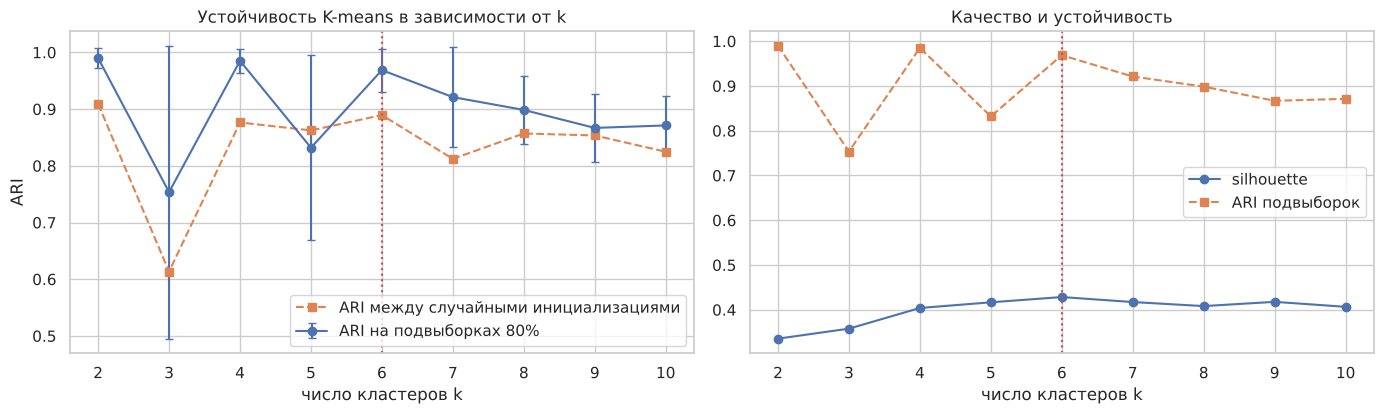

In [18]:
# Влияние числа кластеров k: внутренние метрики (см. таблицу sel) + устойчивость к изменению выборки и инициализации
rng = np.random.default_rng(SEED)
B = 30                                                   # число подвыборок (по 80% объектов)
subs = [rng.choice(len(X), int(0.8 * len(X)), replace=False) for _ in range(B)]

def stability_kmeans(k):
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    ari_sub = [adjusted_rand_score(ref[s], KMeans(n_clusters=k, n_init=10, random_state=b).fit_predict(X[s]))
               for b, s in enumerate(subs)]
    labs = [KMeans(n_clusters=k, n_init=1, random_state=b).fit(X) for b in range(B)]    # одна инициализация на запуск
    ari_seed = [adjusted_rand_score(ref, l.labels_) for l in labs]
    inert = [l.inertia_ for l in labs]
    return np.mean(ari_sub), np.std(ari_sub), np.mean(ari_seed), np.min(ari_seed), np.mean(inert), np.std(inert)

st = pd.DataFrame([stability_kmeans(k) for k in KS], index=pd.Index(KS, name="k"),
                  columns=["ARI подвыборок (ср.)", "ARI подвыборок (σ)", "ARI между запусками n_init=1 (ср.)",
                           "ARI между запусками (мин.)", "inertia (n_init=1, ср.)", "inertia (n_init=1, σ)"])
display(st)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
axes[0].errorbar(KS, st["ARI подвыборок (ср.)"], st["ARI подвыборок (σ)"], fmt="o-", capsize=3, label="ARI на подвыборках 80%")
axes[0].plot(KS, st["ARI между запусками n_init=1 (ср.)"], "s--", label="ARI между случайными инициализациями")
axes[0].axvline(K_KM, color="#C44E52", ls=":"); axes[0].set_xlabel("число кластеров k"); axes[0].set_ylabel("ARI")
axes[0].set_title("Устойчивость K-means в зависимости от k"); axes[0].legend()
axes[1].plot(KS, sel["silhouette K-means"], "o-", label="silhouette"); axes[1].plot(KS, st["ARI подвыборок (ср.)"], "s--", label="ARI подвыборок")
axes[1].axvline(K_KM, color="#C44E52", ls=":"); axes[1].set_xlabel("число кластеров k"); axes[1].set_title("Качество и устойчивость"); axes[1].legend()
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Исследуем влияние **числа кластеров *k*** на результат K-means. Помимо метрик качества (раздел 5), оцениваем устойчивость: (а) ARI между разбиением всей выборки и разбиением 80%-подвыборок (30 повторений, на общих объектах); (б) ARI между разбиениями, полученными при 30 различных случайных инициализациях (`n_init=1`) — показывает, насколько результат зависит от старта. ARI = 1 — полное совпадение (с точностью до перестановки меток), ≈ 0 — случайное.

**Вывод.** С ростом *k* инерция монотонно убывает (389 → 82), поэтому по ней одной выбирать *k* нельзя; качество (силуэт, CH) максимально при *k* = 6. Устойчивость немонотонна: очень высока при *k* = 2 (ARI 0.99), *k* = 4 (0.985) и **k = 6 (0.969 ± 0.038)**, заметно ниже при *k* = 3 (0.75 ± 0.26) и *k* = 5 (0.83 ± 0.16): эти разбиения «перерезают» естественные группы, и положение границы зависит от состава выборки; при *k* ≥ 7 устойчивость снижается до 0.87–0.92, так как естественные группы дробятся на мелкие. Таким образом, *k* = 6 — единственное значение, которое одновременно даёт лучшее качество и высокую устойчивость. При одной инициализации (`n_init=1`) результаты разных запусков при *k* = 6 совпадают лишь частично (средний ARI 0.89, минимум 0.65) — одна случайная инициализация может привести к худшему локальному минимуму.

In [19]:
# Влияние инициализации и n_init на результат K-means при выбранном k
rows = []
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        inert, sil = [], []
        for seed in range(50):
            m = KMeans(n_clusters=K_KM, init=init, n_init=n_init, random_state=seed).fit(X)
            inert.append(m.inertia_); sil.append(silhouette_score(X, m.labels_))
        rows.append({"init": init, "n_init": n_init, "inertia, мин.": np.min(inert), "inertia, макс.": np.max(inert),
                     "inertia, σ": np.std(inert), "доля запусков с лучшей inertia, %": np.mean(np.isclose(inert, np.min(inert), rtol=1e-6)) * 100,
                     "silhouette, ср.": np.mean(sil)})
pd.DataFrame(rows).set_index(["init", "n_init"])

inertia, мин.  inertia, макс.  inertia, σ  доля запусков с лучшей inertia, %  silhouette, ср.
init      n_init                                                                                               
random    1            133.8683        180.4493     12.3723                             6.0000           0.4020
          10           133.8683        133.9578      0.0187                            60.0000           0.4275
k-means++ 1            133.8683        162.7861      9.7967                            12.0000           0.4142
          10           133.8683        134.3528      0.0676                            66.0000           0.4275

**Пояснение к блоку кода.** Для *k* = 6 сравниваем способы инициализации (`random` и `k-means++`) при `n_init` = 1 и 10 на 50 разных зёрнах: диапазон инерции, доля запусков, нашедших лучшее значение, и средний силуэт.

**Вывод.** С одной инициализацией инерция колеблется от 133.87 до 180.4 (случайная) и 162.8 (`k-means++`), а глобально лучший минимум находят лишь 6% и 12% запусков. С `n_init = 10` результат практически стабилен (инерция 133.87–133.96 и 133.87–134.35; лучший минимум в 60–66% запусков, средний силуэт 0.4275 у обоих способов). Поэтому использование `n_init = 10` (как рекомендовано в задании) оправдано, а `k-means++` даёт небольшое преимущество при малом `n_init`.

In [20]:
# Влияние способа расчёта расстояния между кластерами в иерархической кластеризации (k = K_HC)
rows = []
for method in ["ward", "complete", "average", "single"]:
    Zm = linkage(X, method=method)
    lab = fcluster(Zm, t=K_HC, criterion="maxclust") - 1
    rows.append({"linkage": method, "кофенетическая корреляция": cophenet(Zm, pdist(X))[0],
                 "размеры кластеров": sorted(np.bincount(lab).tolist(), reverse=True),
                 "Silhouette": silhouette_score(X, lab), "Calinski–Harabasz": calinski_harabasz_score(X, lab),
                 "Davies–Bouldin": davies_bouldin_score(X, lab),
                 "ARI с Ward": adjusted_rand_score(lab_hc, lab)})
pd.DataFrame(rows).set_index("linkage")

,кофенетическая корреляция,размеры кластеров,Silhouette,Calinski–Harabasz,Davies–Bouldin,ARI с Ward
linkage,,,,,,
ward,0.6262,"[45, 45, 39, 28, 22, 21]",0.4201,127.9865,0.8521,1.0000
complete,0.5931,"[57, 39, 35, 32, 21, 16]",0.3746,109.4154,1.0005,0.7343
average,0.6683,"[54, 52, 39, 31, 20, 4]",0.3896,102.0370,0.8646,0.6947
single,0.5416,"[193, 2, 2, 1, 1, 1]",-0.0428,3.4751,0.6370,0.0113


**Пояснение к блоку кода.** Для иерархической кластеризации сравниваем способы расчёта расстояния между кластерами — Уорд (`ward`), полная связь (`complete`), средняя связь (`average`) и одиночная связь (`single`) — при *k* = 6: кофенетическая корреляция (насколько дендрограмма сохраняет исходные расстояния), размеры кластеров, метрики качества и ARI относительно Уорда.

**Вывод.** Метод Уорда даёт лучшие силуэт (0.420) и CH (128.0) и сбалансированные кластеры (45, 45, 39, 28, 22, 21). Полная и средняя связь дают заметно худшие метрики (силуэт 0.375 и 0.390) и непропорциональные кластеры (у средней связи есть кластер из 4 объектов). Одиночная связь вырождается из-за «эффекта цепочки»: один кластер из 193 объектов и пять из 1–2 (силуэт отрицательный, −0.043; низкий DB = 0.64 здесь обманчив — он оценивает вырожденное разбиение). Кофенетическая корреляция умеренная и сопоставима у разных методов (0.54–0.67; наибольшая у средней связи — 0.668, у Уорда 0.626). Поскольку группы компактные и округлые, метод Уорда — наиболее подходящий способ объединения.

,K-means,Ward
"ARI на подвыборках 80%, ср.",0.9687,0.8117
"ARI на подвыборках 80%, σ",0.0379,0.0649
"ARI при шуме σ=0.1, ср.",0.9435,0.7989
"ARI при шуме σ=0.1, σ",0.0348,0.0514


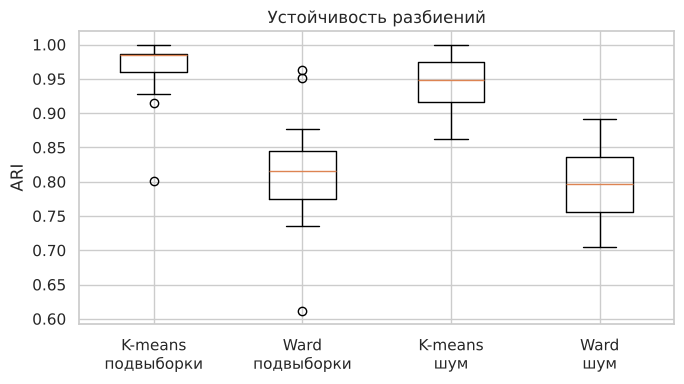

In [21]:
# Устойчивость двух выбранных методов при k = K_KM и k = K_HC: ARI результата на 80%-подвыборке и полного разбиения
ari_km = [adjusted_rand_score(lab_km[s], KMeans(n_clusters=K_KM, n_init=10, random_state=b).fit_predict(X[s])) for b, s in enumerate(subs)]
ari_hc = [adjusted_rand_score(lab_hc[s], AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit_predict(X[s])) for s in subs]

# и с добавлением шума: гауссов шум σ = 0.1 (в единицах стандартизованных признаков)
ari_km_n, ari_hc_n = [], []
for b in range(B):
    Xn = X + np.random.default_rng(1000 + b).normal(0, 0.1, X.shape)
    ari_km_n.append(adjusted_rand_score(lab_km, KMeans(n_clusters=K_KM, n_init=10, random_state=b).fit_predict(Xn)))
    ari_hc_n.append(adjusted_rand_score(lab_hc, AgglomerativeClustering(n_clusters=K_HC, linkage="ward").fit_predict(Xn)))

stab = pd.DataFrame({"K-means": [np.mean(ari_km), np.std(ari_km), np.mean(ari_km_n), np.std(ari_km_n)],
                     "Ward": [np.mean(ari_hc), np.std(ari_hc), np.mean(ari_hc_n), np.std(ari_hc_n)]},
                    index=["ARI на подвыборках 80%, ср.", "ARI на подвыборках 80%, σ", "ARI при шуме σ=0.1, ср.", "ARI при шуме σ=0.1, σ"])
display(stab)
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([ari_km, ari_hc, ari_km_n, ari_hc_n])
ax.set_xticklabels(["K-means\nподвыборки", "Ward\nподвыборки", "K-means\nшум", "Ward\nшум"])
ax.set_ylabel("ARI"); ax.set_title("Устойчивость разбиений"); plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Сравниваем устойчивость двух выбранных методов при *k* = 6: (а) ARI разбиения 80%-подвыборки с разбиением всей выборки (на общих объектах), (б) ARI разбиения данных с добавленным гауссовым шумом σ = 0.1 (в единицах стандартизованных признаков) с исходным разбиением. По 30 повторений.

**Вывод.** K-means устойчивее: ARI на подвыборках 0.969 ± 0.038 против 0.812 ± 0.065 у Уорда, при шуме — 0.944 ± 0.035 против 0.799 ± 0.051. Оба метода дают заметно более высокий ARI, чем случайное разбиение (≈ 0), т.е. выделенные группы воспроизводимы, но для иерархической кластеризации устойчивость ниже: слияния необратимы, и небольшие изменения состава выборки смещают границы кластеров (в первую очередь на границах наименее компактных кластеров). Таким образом, шесть сегментов можно считать устойчивыми, а K-means — более надёжным для этих данных.

## 11. Сравнение методов

In [22]:
def pair_metrics(a, b):
    C = pair_confusion_matrix(a, b)                      # попарная матрица сопряжённости
    same_both, only_a, only_b, diff_both = C[1, 1], C[1, 0], C[0, 1], C[0, 0]
    h, c, v = homogeneity_completeness_v_measure(a, b)
    return {"Rand": rand_score(a, b), "ARI": adjusted_rand_score(a, b),
            "Jaccard (по парам)": same_both / (same_both + only_a + only_b),
            "NMI": normalized_mutual_info_score(a, b), "Homogeneity": h, "Completeness": c, "V-measure": v}

cmp_methods = pd.Series(pair_metrics(lab_km, lab_hc), name="K-means vs Ward")
gender_num = (df["Gender"] == "Male").astype(int).values
cmp_gender = pd.DataFrame({"K-means vs пол": pair_metrics(gender_num, lab_km),
                           "Ward vs пол": pair_metrics(gender_num, lab_hc)})
display(pd.concat([cmp_methods, cmp_gender], axis=1))

print("Таблица сопряжённости (строки — K-means, столбцы — Ward):")
ct = pd.crosstab(pd.Series(lab_km, name="K-means"), pd.Series(lab_hc, name="Ward")); display(ct)
print("Доля объектов, попавших в «основной» кластер Ward для каждого кластера K-means, %:")
print((ct.max(axis=1) / ct.sum(axis=1) * 100).round(1).to_dict())
diff = df[pd.crosstab(lab_km, lab_hc).values.argmax(1)[lab_km] != lab_hc][FEATURES + ["KMeans", "Ward"]]
print("Число объектов, на которых методы расходятся:", len(diff))
display(diff.head(12))

,K-means vs Ward,K-means vs пол,Ward vs пол
Rand,0.9685,0.4962,0.4938
ARI,0.8914,-0.0014,-0.0063
Jaccard (по парам),0.8356,0.1480,0.1484
NMI,0.9004,0.0081,0.0027
Homogeneity,0.8975,0.0144,0.0047
Completeness,0.9032,0.0056,0.0018
V-measure,0.9004,0.0081,0.0027


Таблица сопряжённости (строки — K-means, столбцы — Ward):


Ward,0,1,2,3,4,5
K-means,,,,,,
0,21,1,0,1,0,0
1,0,21,0,0,0,0
2,0,0,43,2,0,0
3,0,0,0,39,0,0
4,0,0,0,0,39,0
5,0,0,2,3,0,28


Доля объектов, попавших в «основной» кластер Ward для каждого кластера K-means, %:
{0: 91.3, 1: 100.0, 2: 95.6, 3: 100.0, 4: 100.0, 5: 84.8}
Число объектов, на которых методы расходятся: 9


,Age,Income,Spending,KMeans,Ward
0,19,15,39,0,1
27,35,28,61,0,3
66,43,48,50,2,3
76,45,54,53,2,3
126,43,71,35,5,2
134,20,73,5,5,3
144,25,77,12,5,3
146,48,77,36,5,2
162,19,81,5,5,3


**Пояснение к блоку кода.** Сравниваем два разбиения с помощью внешних метрик, которые измеряют согласованность двух разбиений независимо от нумерации кластеров: индекс Rand (RI), скорректированный ARI, индекс Жаккара по парам объектов, NMI, однородность, полнота и V-мера. Дополнительно эти метрики рассчитаны между каждым разбиением и полом клиентов — это не истинные классы, а демографическая переменная, проверка того, не воспроизводят ли кластеры пол. Далее — таблица сопряжённости и объекты, на которых методы расходятся.

**Вывод.** Методы согласованы очень хорошо: RI = 0.969, ARI = 0.891, Жаккар = 0.836, NMI = V-мера = 0.900 (однородность 0.898, полнота 0.903). По таблице сопряжённости кластеры 1, 3 и 4 совпадают полностью (21, 39 и 39 объектов), кластеры 0 и 2 — на 91% и 96%, и только кластер 5 разделён заметно (85% объектов). Всего методы расходятся на **9 объектов из 200** (4.5%) — это пограничные клиенты, например, молодые клиенты с доходом 73–81 и очень низкими тратами (5–12), которые K-means относит к «богатым экономным» (кластер 5), а Уорд — к «молодым середнякам» (кластер 3). Связь с полом отсутствует: ARI ≈ −0.001 и −0.006, NMI < 0.01 — кластеры не воспроизводят пол и описывают поведенческие, а не демографические различия, как и должно быть при сегментации по доходу, тратам и возрасту.

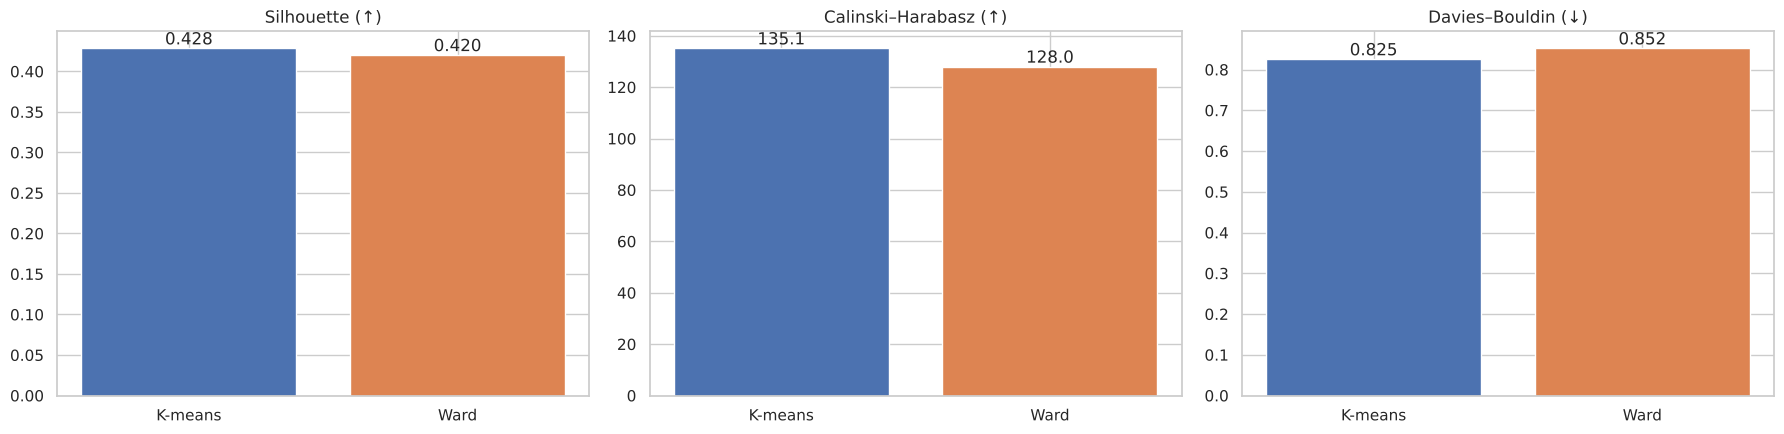

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cols = ["Silhouette (↑)", "Calinski–Harabasz (↑)", "Davies–Bouldin (↓)"]
for ax, m in zip(axes, cols):
    vals = qual.loc[m]; ax.bar(vals.index, vals.values, color=["#4C72B0", "#DD8452"])
    for i, v in enumerate(vals.values): ax.text(i, v, f"{v:.3f}" if v < 10 else f"{v:.1f}", ha="center", va="bottom")
    ax.set_title(m)
plt.tight_layout(); plt.show()

**Пояснение к блоку кода.** Столбчатые диаграммы сравнивают методы по основным внутренним метрикам: силуэт (↑), индекс CH (↑), индекс DB (↓).

**Вывод.** По всем трём метрикам K-means незначительно лучше (силуэт 0.428 против 0.420, CH 135 против 128, DB 0.825 против 0.852). Для этих данных (компактные округлые кластеры одного масштаба) K-means предпочтительнее: лучше по метрикам, существенно устойчивее (ARI 0.97 против 0.81), вычислительно проще. Метод Уорда ценен как независимая проверка и за дендрограмму — именно по ней подтверждено *k* = 6, а совпадение двух методов (ARI 0.89) говорит о том, что структура данных реальна, а не артефакт алгоритма.

## Заключение

1. **Данные.** Датасет Mall Customer Segmentation: 200 клиентов, три числовых признака (`Age`, `Income`, `Spending`) и пол. Пропусков и дубликатов нет, признаки близки к симметричным (асимметрия |γ| ≤ 0.49), строго нормальными не являются (критерий Шапиро–Уилка), но для K-means и метода Уорда это не критично. Признаки слабо коррелируют (кроме `Age`–`Spending`, r = −0.33), PCA показывает равномерный вклад всех трёх, пол различий не даёт — в кластеризации использованы три числовых признака.
2. **Условия применимости.** Классов нет; выбросов по правилу трёх сигм нет (два клиента с доходом 137 тыс. отмечены только по IQR и оставлены); статистика Хопкинса 0.69 (при 0.48 для равномерных данных) — структура есть, но выражена умеренно. Кластеризация осмысленна.
3. **Подготовка.** Применён `StandardScaler`: методы основаны на евклидовом расстоянии, признаки измерены в разных единицах; стандартизация сохраняет форму распределений, а min–max зависела бы от крайних значений. Матрица рассеивания показала пять компактных округлых групп по доходу и тратам, а возраст делит центральную группу на две — ожидаемо 5–6 кластеров округлой формы, разреженных на периферии и плотных в центре. Поэтому выбраны K-means и иерархическая кластеризация Уорда (DBSCAN не подходит из-за отсутствия плотностных разрывов, GMM — избыточен при n = 200).
4. **Число кластеров.** Метод локтя неоднозначен (4–6), силуэт и индекс Калинского–Харабаза дают максимум при *k* = 6 для обоих методов, дендрограмма Уорда подтверждает *k* = 6 (самый длинный интервал высот после *k* = 2). Принято **k = 6**.
5. **Качество.** K-means: силуэт 0.428, CH 135.1, DB 0.825, WCSS 133.9; Уорд: 0.420, 128.0, 0.852, 139.6. Структура умеренная (силуэт ≈ 0.43): кластеры компактны (среднее расстояние до центра ≈ 0.75 при расстоянии между центрами ≥ 1.67), но соседние группы примыкают друг к другу (индекс Данна ≈ 0.06–0.07).
6. **Влияние параметров.** Число кластеров *k*: качество и устойчивость одновременно максимальны при *k* = 6; при *k* = 3 и 5 разбиения неустойчивы (ARI 0.75 и 0.83). Инициализация: при `n_init = 1` лучший минимум находится лишь в 6–12% запусков, при `n_init = 10` — результат стабилен. Способ связи: Уорд заметно лучше полной, средней и особенно одиночной связи (эффект цепочки).
7. **Интерпретация.** Выделены шесть сегментов: «молодые транжиры» (низкий доход, высокие траты), «экономные с низким доходом», «возрастные середняки», «молодые середняки», «целевая аудитория» (высокий доход и траты) и «богатые экономные» (высокий доход, низкие траты). Последние — наиболее перспективны для маркетинга как неиспользованный потенциал; сегмент 4 — самый ценный.
8. **Сравнение и устойчивость.** Методы согласованы (ARI 0.89, NMI 0.90, Жаккар 0.84; расхождение на 9 из 200 объектов, все на границах кластеров); кластеры не связаны с полом (ARI ≈ 0). K-means немного лучше по метрикам и заметно устойчивее (ARI на подвыборках 0.97 против 0.81), поэтому для итоговой сегментации рекомендуется K-means с *k* = 6; метод Уорда служит независимым подтверждением. Ограничения: небольшая выборка (200 клиентов) и умеренная разделённость групп — клиенты на границах кластеров (особенно в центре) могут менять сегмент при небольших изменениях данных.

## Список источников

1. Dataset: *Mall Customer Segmentation Data* [Электронный ресурс] // Kaggle. — https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python (дата обращения: 24.11.2026).
2. Pedregosa F. et al. *Scikit-learn: Machine Learning in Python* // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830. Документация: https://scikit-learn.org/stable/modules/clustering.html (разделы «K-means», «Hierarchical clustering», «Clustering performance evaluation»).
3. Rousseeuw P. J. *Silhouettes: a graphical aid to the interpretation and validation of cluster analysis* // Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
4. Caliński T., Harabasz J. *A dendrite method for cluster analysis* // Communications in Statistics. — 1974. — Vol. 3, № 1. — P. 1–27.
5. Hopkins B., Skellam J. G. *A new method for determining the type of distribution of plant individuals* // Annals of Botany. — 1954. — Vol. 18. — P. 213–227.
6. Hubert L., Arabie P. *Comparing partitions* // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
7. Ward J. H. *Hierarchical grouping to optimize an objective function* // Journal of the American Statistical Association. — 1963. — Vol. 58. — P. 236–244.